### EDA

IFN3-IFN4: faltantes, estadisticos y demás

/tmp/ipykernel_3054068/324183.py:10: DtypeWarning: Columns (0: orientacion_cat, 1: pendiente_cat) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(ruta_ifn3)


✅ CSV cargado: bbdd/ifn3_ifn4.csv
Shape: (119864, 57)


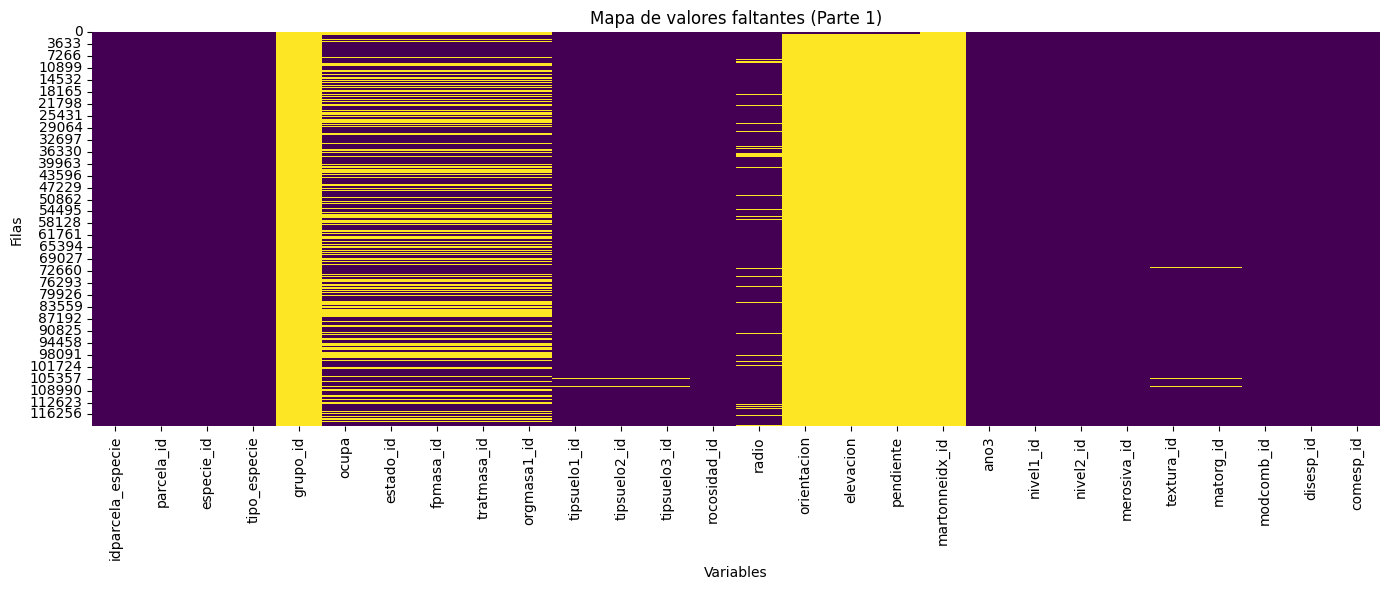

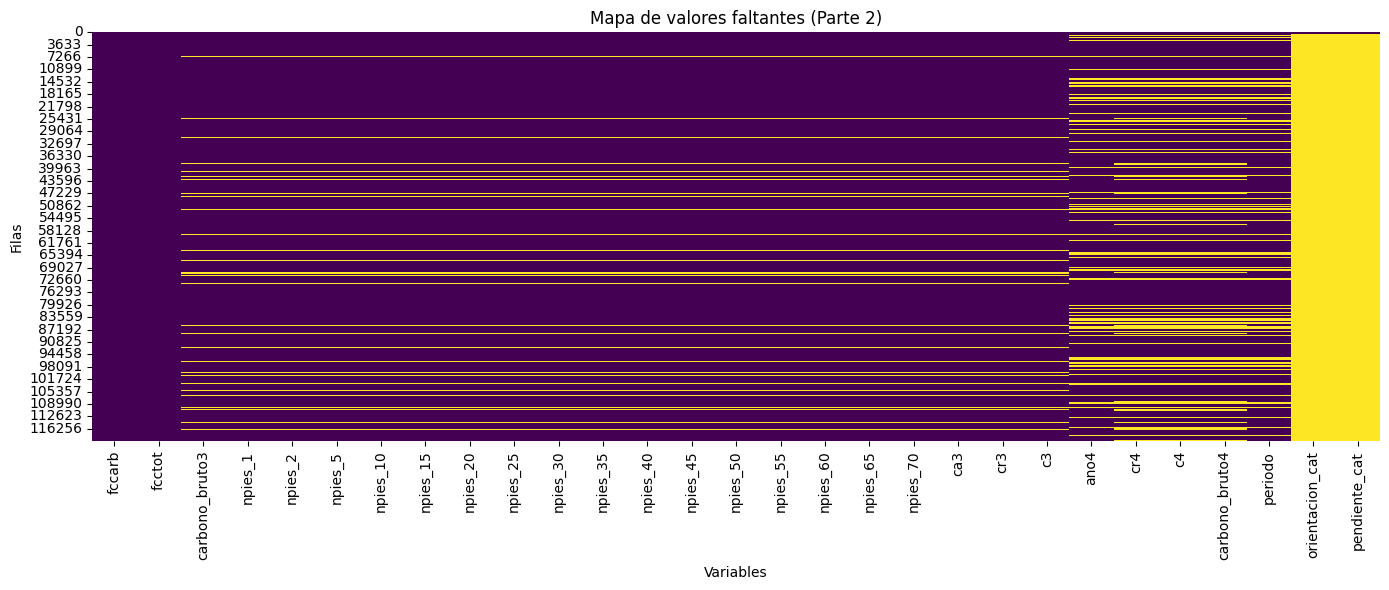


--- Variables con valores faltantes ---
grupo_id           119864
martonneidx_id     119864
pendiente          119369
orientacion        119369
elevacion          119369
pendiente_cat      119369
orientacion_cat    119369
fpmasa_id           46698
tratmasa_id         46694
orgmasa1_id         46693
estado_id           46693
ocupa               46693
c4                  30853
cr4                 30853
carbono_bruto4      30853
periodo             27084
ano4                27075
carbono_bruto3       8227
npies_2              8168
npies_1              8168
npies_35             8168
cr3                  8168
ca3                  8168
npies_70             8168
npies_65             8168
npies_60             8168
npies_40             8168
npies_30             8168
npies_45             8168
npies_50             8168
npies_55             8168
c3                   8168
npies_25             8168
npies_20             8168
npies_15             8168
npies_10             8168
npies_5              81

          especie_id   tipo_especie  grupo_id         ocupa     estado_id  \
count  119864.000000  119805.000000       0.0  73171.000000  73171.000000   
mean       78.537726       0.672284       NaN      5.223449      3.161772   
std        92.822319       0.469383       NaN      3.211234      0.858263   
min         1.000000       0.000000       NaN      1.000000      1.000000   
25%        26.000000       0.000000       NaN      2.000000      3.000000   
50%        45.000000       1.000000       NaN      5.000000      3.000000   
75%        71.000000       1.000000       NaN      8.000000      4.000000   
max       957.000000       1.000000       NaN     10.000000      4.000000   

          fpmasa_id   tratmasa_id   orgmasa1_id   tipsuelo1_id   tipsuelo2_id  \
count  73166.000000  73170.000000  73171.000000  118337.000000  118337.000000   
mean       3.528962      1.571778      1.317653       1.018566       1.724245   
std        0.733050      0.538320      0.660341       0.220551 

/tmp/ipykernel_3054068/324183.py:58: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.describe(include=[object]))


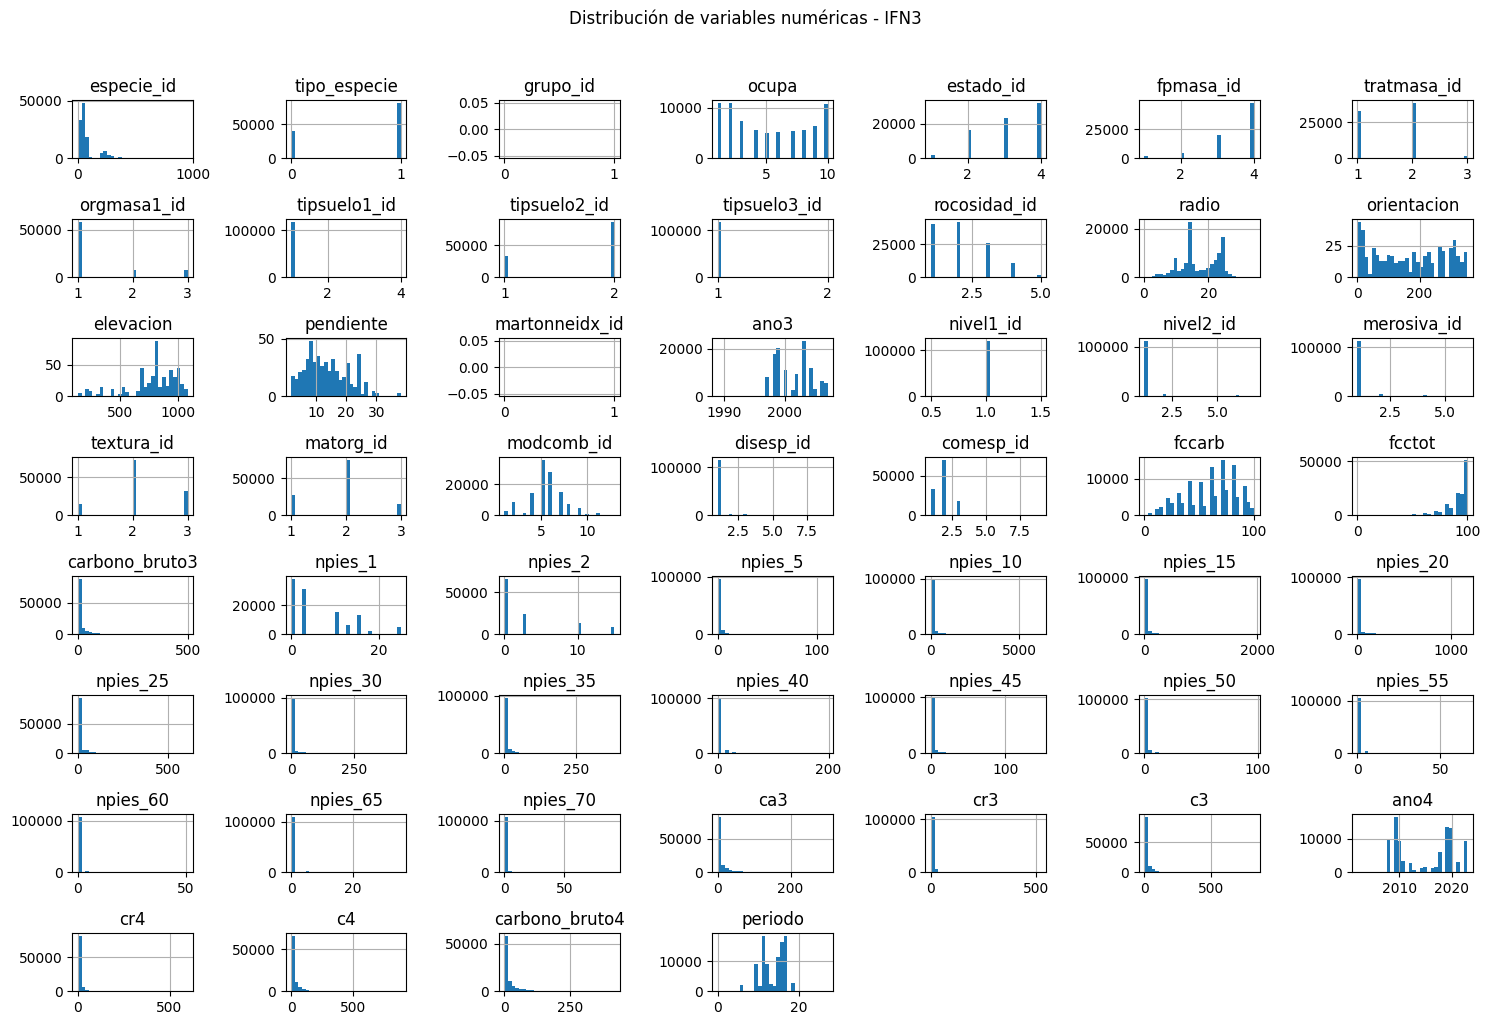

/tmp/ipykernel_3054068/324183.py:73: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = [c for c in df.select_dtypes(include=["object"]).columns if df[c].nunique() <= 20]


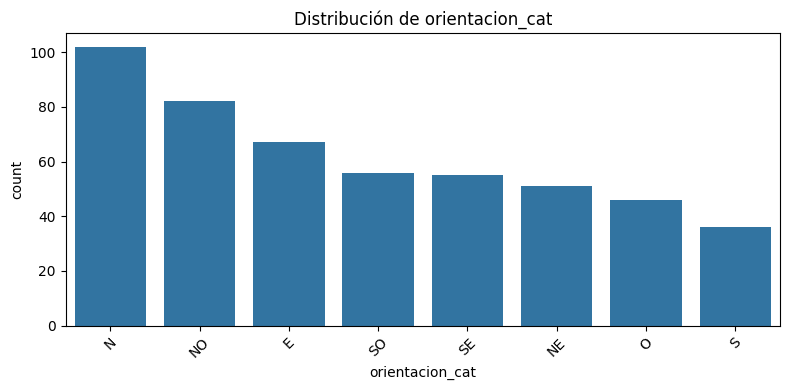

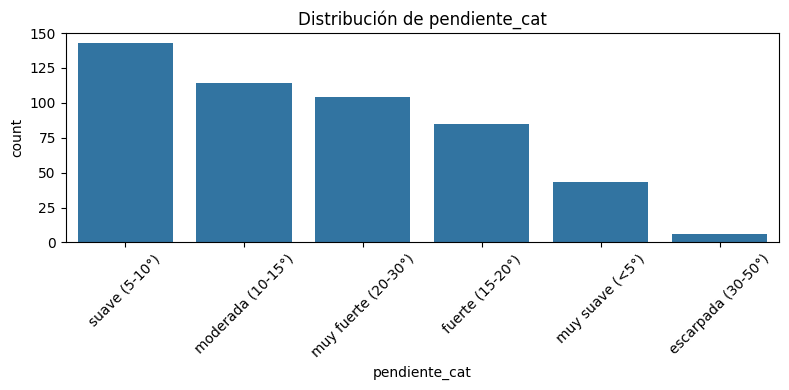

In [1]:
# -*- coding: utf-8 -*-
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# =========================
# 1) Cargar CSV IFN3
# =========================
ruta_ifn3 = "bbdd/ifn3_ifn4.csv"
df = pd.read_csv(ruta_ifn3)

print("✅ CSV cargado:", ruta_ifn3)
print("Shape:", df.shape)

# =========================
# 2) Faltantes con heatmap dividido
# =========================
n_cols = len(df.columns)
mid = n_cols // 2

plt.figure(figsize=(14, 6))
sns.heatmap(df.iloc[:, :mid].isnull(), cbar=False, cmap="viridis")
plt.title("Mapa de valores faltantes (Parte 1)")
plt.xlabel("Variables")
plt.ylabel("Filas")
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 6))
sns.heatmap(df.iloc[:, mid:].isnull(), cbar=False, cmap="viridis")
plt.title("Mapa de valores faltantes (Parte 2)")
plt.xlabel("Variables")
plt.ylabel("Filas")
plt.tight_layout()
plt.show()

# =========================
# 3) Resumen de faltantes
# =========================
faltantes = df.isnull().sum()
faltantes = faltantes[faltantes > 0].sort_values(ascending=False)
print("\n--- Variables con valores faltantes ---")
print(faltantes)

# =========================
# 4) EDA rápido
# =========================
print("\n--- Tipos de variables ---")
print(df.dtypes)

print("\n--- Número de valores únicos por variable ---")
print(df.nunique().sort_values(ascending=False))

print("\n--- Estadísticos básicos (numéricas) ---")
print(df.describe(include=[float, int]))

print("\n--- Estadísticos básicos (categóricas) ---")
print(df.describe(include=[object]))

# =========================
# 5) Histogramas numéricos
# =========================
num_cols = df.select_dtypes(include=["number"]).columns
if len(num_cols) > 0:
    df[num_cols].hist(figsize=(15,10), bins=30)
    plt.suptitle("Distribución de variables numéricas - IFN3", y=1.02)
    plt.tight_layout()
    plt.show()

# =========================
# 6) Barras para categóricas con <= 20 categorías
# =========================
cat_cols = [c for c in df.select_dtypes(include=["object"]).columns if df[c].nunique() <= 20]
for c in cat_cols:
    plt.figure(figsize=(8,4))
    sns.countplot(data=df, x=c, order=df[c].value_counts().index)
    plt.title(f"Distribución de {c}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


IFN3-IFN4: conteo de entradas válidas para el modelo (aplicando filtros)

estudio de fccarb

=== INFORME DE LA VARIABLE fccarb ===
Total de filas:        135024
Valores válidos:       119853
Valores nulos:         15171 (11.24%)

=== ESTADÍSTICOS BÁSICOS ===
count    119853.000000
mean         59.888305
std          23.005602
min           0.000000
25%          40.000000
50%          65.000000
75%          80.000000
max         100.000000
Name: fccarb, dtype: float64

=== PERCENTILES ===
0.01     10.0
0.05     20.0
0.25     40.0
0.50     65.0
0.75     80.0
0.95     90.0
0.99    100.0
Name: fccarb, dtype: float64

=== VALORES ATÍPICOS (OUTLIERS) ===
Número de outliers: 0
Rango intercuartílico (IQR): 40.000
Límite inferior: -20.000
Límite superior: 140.000


/tmp/ipykernel_3054068/451374865.py:5: DtypeWarning: Columns (0: orientacion_cat, 1: pendiente_cat) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("bbdd/ifn_entrenamiento.csv")


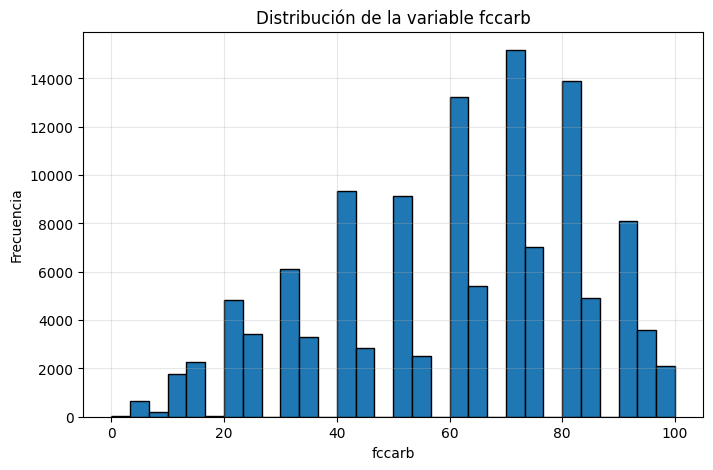

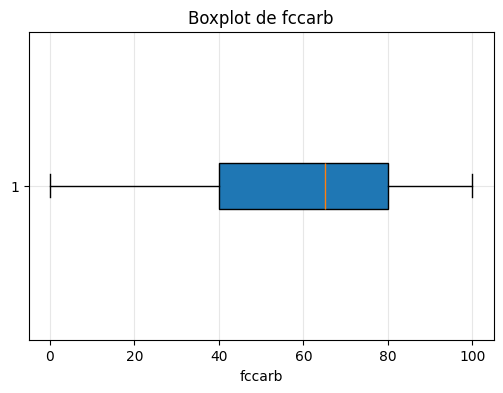

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# === Cargar datos ===
df = pd.read_csv("bbdd/ifn_entrenamiento.csv")

# === Verificar que existe la columna ===
if "fccarb" not in df.columns:
    raise KeyError("No se encuentra la columna 'fccarb' en el CSV.")

# === Eliminar valores nulos para análisis ===
fccarb = df["fccarb"].dropna()
n_total = len(df)
n_validos = len(fccarb)
n_nulos = n_total - n_validos

print("=== INFORME DE LA VARIABLE fccarb ===")
print(f"Total de filas:        {n_total}")
print(f"Valores válidos:       {n_validos}")
print(f"Valores nulos:         {n_nulos} ({(n_nulos/n_total*100):.2f}%)\n")

# === Estadísticos básicos ===
print("=== ESTADÍSTICOS BÁSICOS ===")
print(fccarb.describe())

# === Percentiles personalizados ===
percentiles = fccarb.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
print("\n=== PERCENTILES ===")
print(percentiles)

# === Detección simple de valores extremos (IQR) ===
Q1 = fccarb.quantile(0.25)
Q3 = fccarb.quantile(0.75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = fccarb[(fccarb < limite_inferior) | (fccarb > limite_superior)]
print("\n=== VALORES ATÍPICOS (OUTLIERS) ===")
print(f"Número de outliers: {len(outliers)}")
print(f"Rango intercuartílico (IQR): {IQR:.3f}")
print(f"Límite inferior: {limite_inferior:.3f}")
print(f"Límite superior: {limite_superior:.3f}")

# === Histograma ===
plt.figure(figsize=(8,5))
plt.hist(fccarb, bins=30, edgecolor='black')
plt.title("Distribución de la variable fccarb")
plt.xlabel("fccarb")
plt.ylabel("Frecuencia")
plt.grid(alpha=0.3)
plt.show()

# === Boxplot ===
plt.figure(figsize=(6,4))
plt.boxplot(fccarb, vert=False, patch_artist=True)
plt.title("Boxplot de fccarb")
plt.xlabel("fccarb")
plt.grid(alpha=0.3)
plt.show()


--- RESULTADOS ---
Entradas con fccarb > 20: 158,434
Entradas con c4 no nulo: 122,957
Entradas con c3 <= c4: 102,293
Entradas con fccarb > 20 y c3 <= c4: 95,659
Entradas con fccarb > 20: 158,434
Entradas con carbono_bruto4 no nulo: 122,957
Entradas con carbono_bruto3 <= carbono_bruto4: 90,641
Entradas con fccarb > 20 y carbono_bruto3 <= carbono_bruto4: 84,692

IFN2-IFN4:  faltantes, estadisticos y demás

✅ CSV cargado: bbdd/ifn2_ifn4.csv
Shape: (15160, 57)


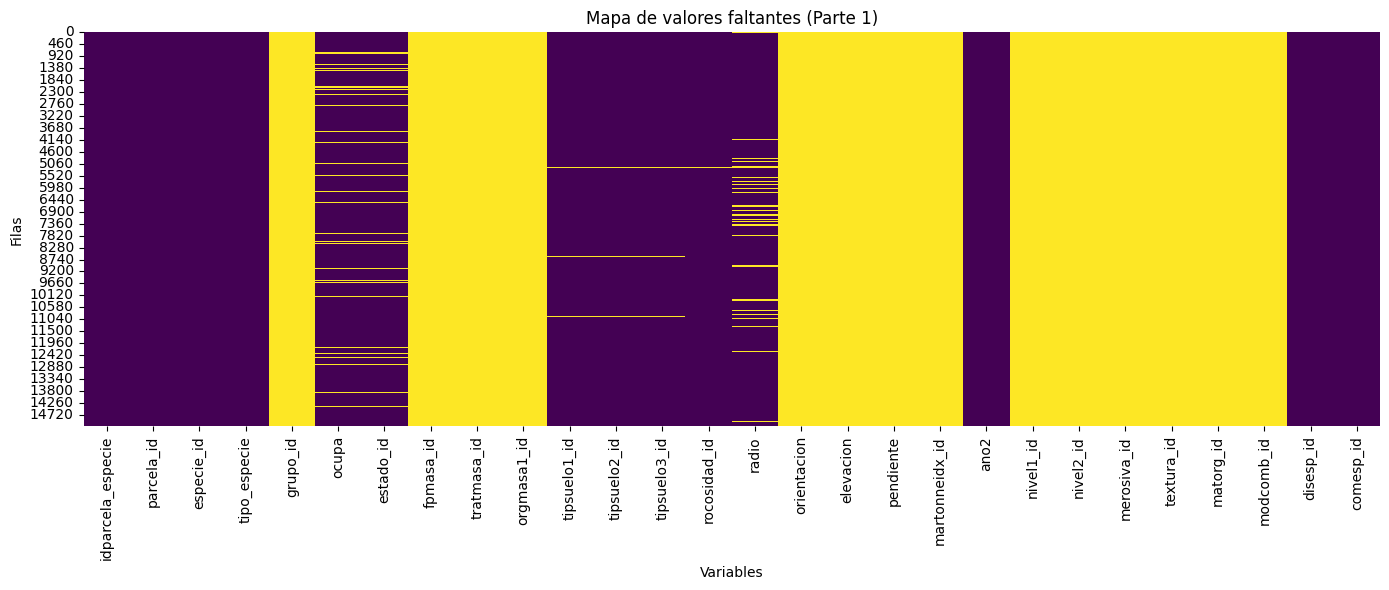

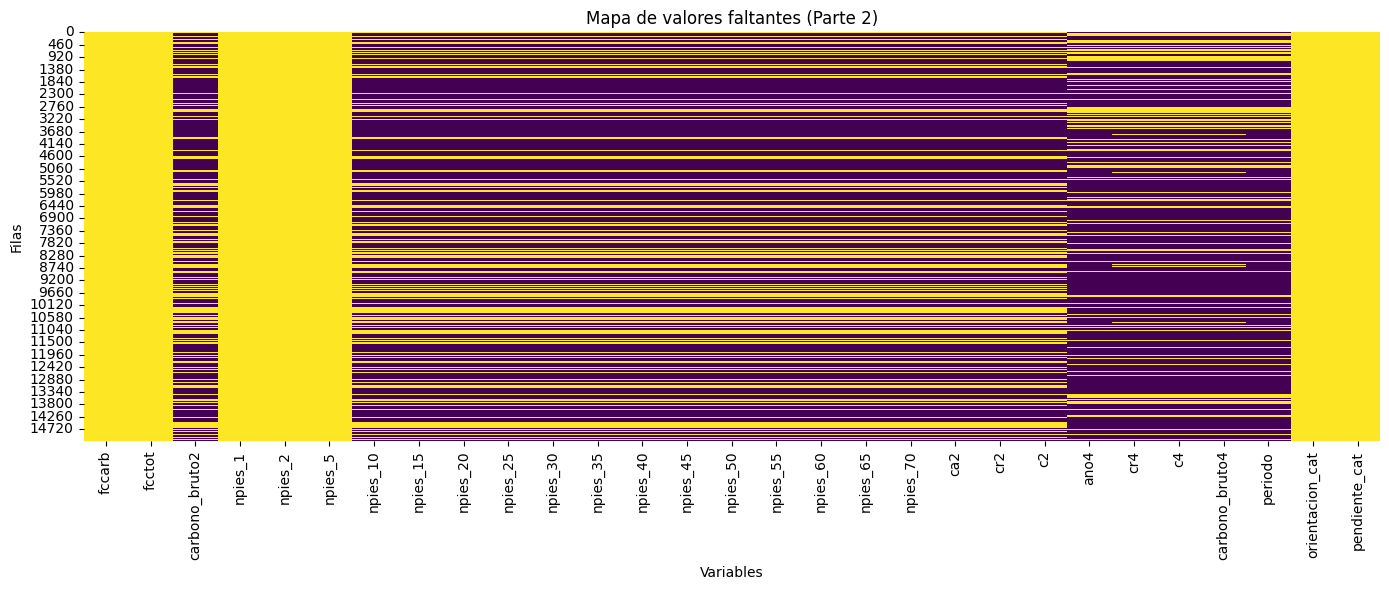


--- Variables con valores faltantes ---
grupo_id           15160
fpmasa_id          15160
orgmasa1_id        15160
tratmasa_id        15160
textura_id         15160
merosiva_id        15160
orientacion        15160
nivel2_id          15160
nivel1_id          15160
martonneidx_id     15160
pendiente          15160
elevacion          15160
matorg_id          15160
orientacion_cat    15160
npies_5            15160
npies_2            15160
fcctot             15160
npies_1            15160
fccarb             15160
modcomb_id         15160
pendiente_cat      15160
cr2                 5246
npies_45            5246
ca2                 5246
npies_65            5246
npies_70            5246
npies_55            5246
npies_50            5246
npies_25            5246
npies_30            5246
npies_15            5246
npies_20            5246
npies_35            5246
npies_40            5246
npies_10            5246
carbono_bruto2      5246
c2                  5246
npies_60            5246
carbono_b

/tmp/ipykernel_3054068/2513468410.py:58: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.describe(include=[object]))


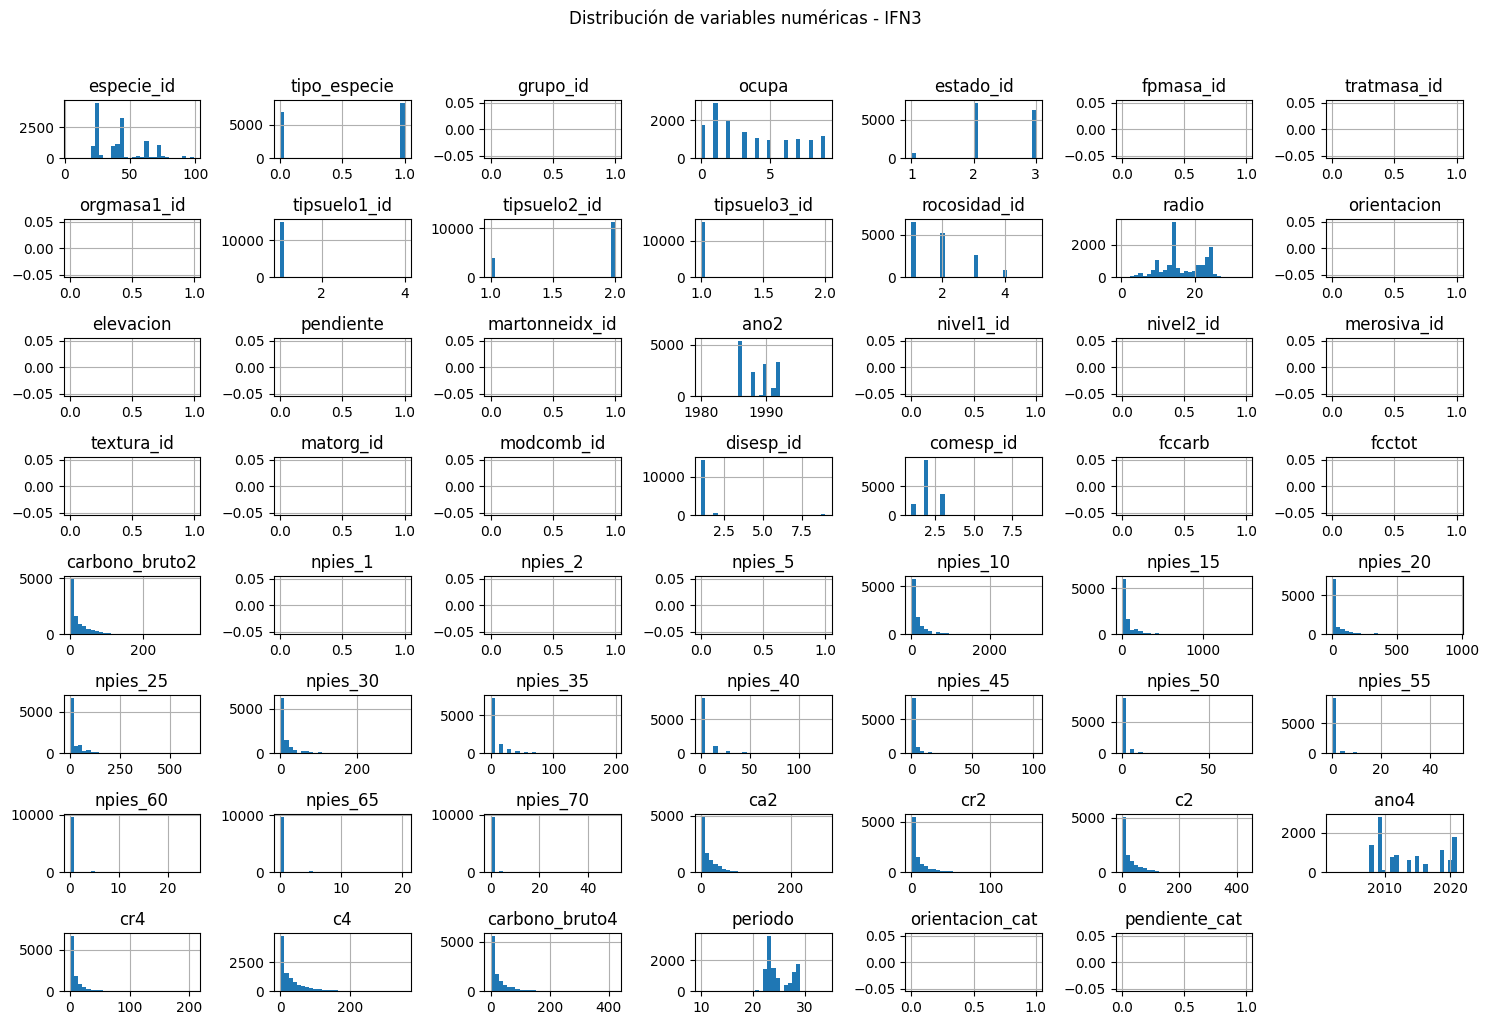

/tmp/ipykernel_3054068/2513468410.py:73: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = [c for c in df.select_dtypes(include=["object"]).columns if df[c].nunique() <= 20]


In [3]:
# -*- coding: utf-8 -*-
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# =========================
# 1) Cargar CSV IFN3
# =========================
ruta_ifn3 = "bbdd/ifn2_ifn4.csv"
df = pd.read_csv(ruta_ifn3)

print("✅ CSV cargado:", ruta_ifn3)
print("Shape:", df.shape)

# =========================
# 2) Faltantes con heatmap dividido
# =========================
n_cols = len(df.columns)
mid = n_cols // 2

plt.figure(figsize=(14, 6))
sns.heatmap(df.iloc[:, :mid].isnull(), cbar=False, cmap="viridis")
plt.title("Mapa de valores faltantes (Parte 1)")
plt.xlabel("Variables")
plt.ylabel("Filas")
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 6))
sns.heatmap(df.iloc[:, mid:].isnull(), cbar=False, cmap="viridis")
plt.title("Mapa de valores faltantes (Parte 2)")
plt.xlabel("Variables")
plt.ylabel("Filas")
plt.tight_layout()
plt.show()

# =========================
# 3) Resumen de faltantes
# =========================
faltantes = df.isnull().sum()
faltantes = faltantes[faltantes > 0].sort_values(ascending=False)
print("\n--- Variables con valores faltantes ---")
print(faltantes)

# =========================
# 4) EDA rápido
# =========================
print("\n--- Tipos de variables ---")
print(df.dtypes)

print("\n--- Número de valores únicos por variable ---")
print(df.nunique().sort_values(ascending=False))

print("\n--- Estadísticos básicos (numéricas) ---")
print(df.describe(include=[float, int]))

print("\n--- Estadísticos básicos (categóricas) ---")
print(df.describe(include=[object]))

# =========================
# 5) Histogramas numéricos
# =========================
num_cols = df.select_dtypes(include=["number"]).columns
if len(num_cols) > 0:
    df[num_cols].hist(figsize=(15,10), bins=30)
    plt.suptitle("Distribución de variables numéricas - IFN3", y=1.02)
    plt.tight_layout()
    plt.show()

# =========================
# 6) Barras para categóricas con <= 20 categorías
# =========================
cat_cols = [c for c in df.select_dtypes(include=["object"]).columns if df[c].nunique() <= 20]
for c in cat_cols:
    plt.figure(figsize=(8,4))
    sns.countplot(data=df, x=c, order=df[c].value_counts().index)
    plt.title(f"Distribución de {c}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


----------------
EDA Carbono

IFN3-IFN4: eda carbono

/tmp/ipykernel_3054068/1181334243.py:8: DtypeWarning: Columns (0: orientacion_cat, 1: pendiente_cat) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(ruta)


Coeficiente de correlación (r): 0.8097
Ecuación de regresión: carbono_bruto4 = 5.538 + 0.918 * carbono_bruto3
R² (regresión): 0.6556
p-valor: 0.00e+00


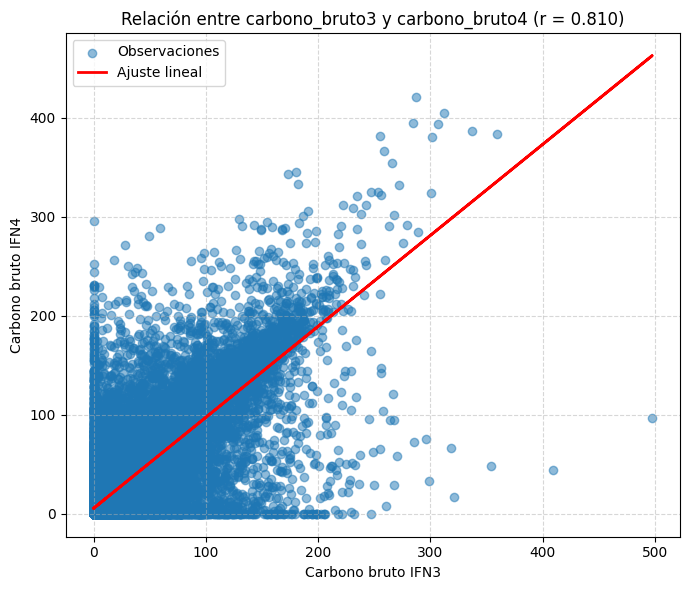

In [4]:
# -*- coding: utf-8 -*-
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

# === 1) Cargar los datos ===
ruta = "bbdd/ifn3_ifn4.csv"
df = pd.read_csv(ruta)

# Verificar que las columnas existen
if not {'carbono_bruto3', 'carbono_bruto4'}.issubset(df.columns):
    raise KeyError("El archivo no contiene las columnas 'carbono_bruto3' y 'carbono_bruto4'.")

# Eliminar posibles NaN
df = df.dropna(subset=['carbono_bruto3', 'carbono_bruto4'])

# === 2) Calcular correlación y ajuste lineal ===
corr = df['carbono_bruto3'].corr(df['carbono_bruto4'])
slope, intercept, r_value, p_value, std_err = linregress(df['carbono_bruto3'], df['carbono_bruto4'])

print(f"Coeficiente de correlación (r): {corr:.4f}")
print(f"Ecuación de regresión: carbono_bruto4 = {intercept:.3f} + {slope:.3f} * carbono_bruto3")
print(f"R² (regresión): {r_value**2:.4f}")
print(f"p-valor: {p_value:.2e}")

# === 3) Gráfico de dispersión con línea de ajuste ===
plt.figure(figsize=(7,6))
plt.scatter(df['carbono_bruto3'], df['carbono_bruto4'], alpha=0.5, label='Observaciones')
plt.plot(df['carbono_bruto3'], intercept + slope * df['carbono_bruto3'], color='red', linewidth=2, label='Ajuste lineal')
plt.xlabel("Carbono bruto IFN3")
plt.ylabel("Carbono bruto IFN4")
plt.title(f"Relación entre carbono_bruto3 y carbono_bruto4 (r = {corr:.3f})")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


/tmp/ipykernel_3054068/3297929668.py:8: DtypeWarning: Columns (0: orientacion_cat, 1: pendiente_cat) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(ruta)


Coeficiente de correlación (r): 0.8356
Ecuación de regresión: c4 = 6.416 + 0.973 * c3
R² (regresión): 0.6983
p-valor: 0.00e+00


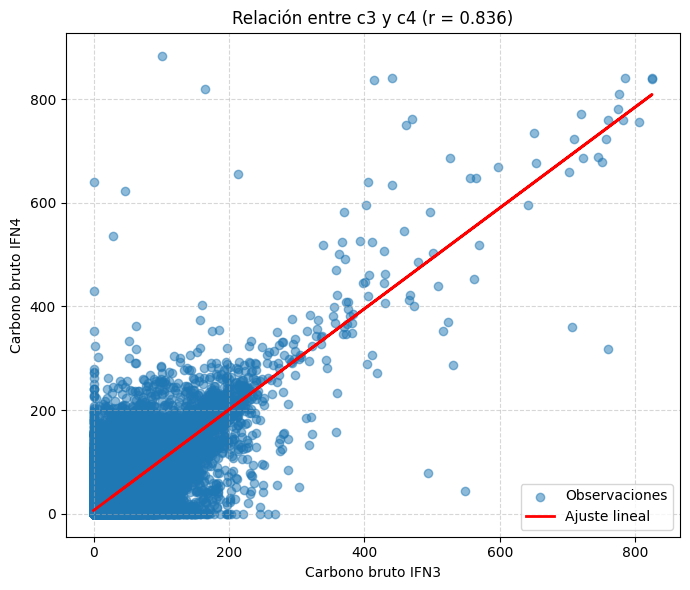

In [5]:
# -*- coding: utf-8 -*-
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

# === 1) Cargar los datos ===
ruta = "bbdd/ifn3_ifn4.csv"
df = pd.read_csv(ruta)

# Verificar que las columnas existen
if not {'c3', 'c4'}.issubset(df.columns):
    raise KeyError("El archivo no contiene las columnas 'c3' y 'c4'.")

# Eliminar posibles NaN
df = df.dropna(subset=['c3', 'c4'])

# === 2) Calcular correlación y ajuste lineal ===
corr = df['c3'].corr(df['c4'])
slope, intercept, r_value, p_value, std_err = linregress(df['c3'], df['c4'])

print(f"Coeficiente de correlación (r): {corr:.4f}")
print(f"Ecuación de regresión: c4 = {intercept:.3f} + {slope:.3f} * c3")
print(f"R² (regresión): {r_value**2:.4f}")
print(f"p-valor: {p_value:.2e}")

# === 3) Gráfico de dispersión con línea de ajuste ===
plt.figure(figsize=(7,6))
plt.scatter(df['c3'], df['c4'], alpha=0.5, label='Observaciones')
plt.plot(df['c3'], intercept + slope * df['c3'], color='red', linewidth=2, label='Ajuste lineal')
plt.xlabel("Carbono bruto IFN3")
plt.ylabel("Carbono bruto IFN4")
plt.title(f"Relación entre c3 y c4 (r = {corr:.3f})")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


IFN2-IFN4: eda carbono

Coeficiente de correlación (r): 0.5412
Ecuación de regresión: carbono_bruto4 = 16.004 + 0.749 * carbono_bruto2
R² (regresión): 0.2929
p-valor: 0.00e+00


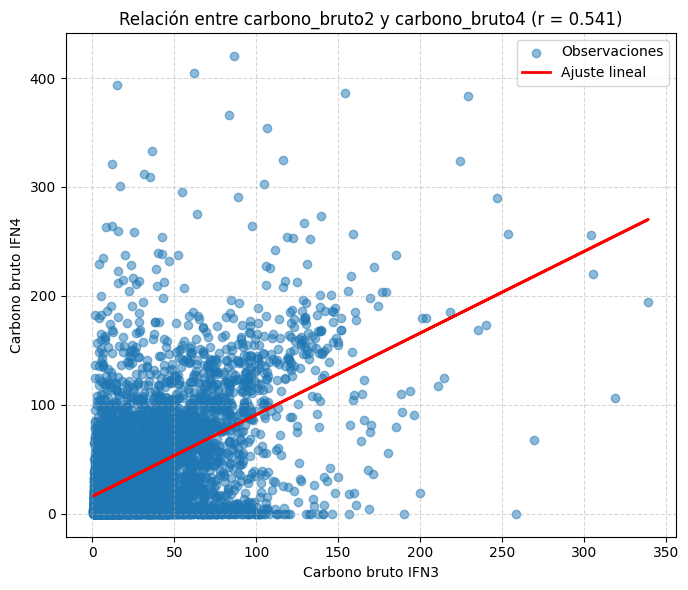

In [6]:
# -*- coding: utf-8 -*-
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

# === 1) Cargar los datos ===
ruta = "bbdd/ifn2_ifn4.csv"
df = pd.read_csv(ruta)

# Verificar que las columnas existen
if not {'carbono_bruto2', 'carbono_bruto4'}.issubset(df.columns):
    raise KeyError("El archivo no contiene las columnas 'carbono_bruto2' y 'carbono_bruto4'.")

# Eliminar posibles NaN
df = df.dropna(subset=['carbono_bruto2', 'carbono_bruto4'])

# === 2) Calcular correlación y ajuste lineal ===
corr = df['carbono_bruto2'].corr(df['carbono_bruto4'])
slope, intercept, r_value, p_value, std_err = linregress(df['carbono_bruto2'], df['carbono_bruto4'])

print(f"Coeficiente de correlación (r): {corr:.4f}")
print(f"Ecuación de regresión: carbono_bruto4 = {intercept:.3f} + {slope:.3f} * carbono_bruto2")
print(f"R² (regresión): {r_value**2:.4f}")
print(f"p-valor: {p_value:.2e}")

# === 3) Gráfico de dispersión con línea de ajuste ===
plt.figure(figsize=(7,6))
plt.scatter(df['carbono_bruto2'], df['carbono_bruto4'], alpha=0.5, label='Observaciones')
plt.plot(df['carbono_bruto2'], intercept + slope * df['carbono_bruto2'], color='red', linewidth=2, label='Ajuste lineal')
plt.xlabel("Carbono bruto IFN3")
plt.ylabel("Carbono bruto IFN4")
plt.title(f"Relación entre carbono_bruto2 y carbono_bruto4 (r = {corr:.3f})")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


Coeficiente de correlación (r): 0.4481
Ecuación de regresión: c4 = 22.650 + 0.590 * c2
R² (regresión): 0.2008
p-valor: 0.00e+00


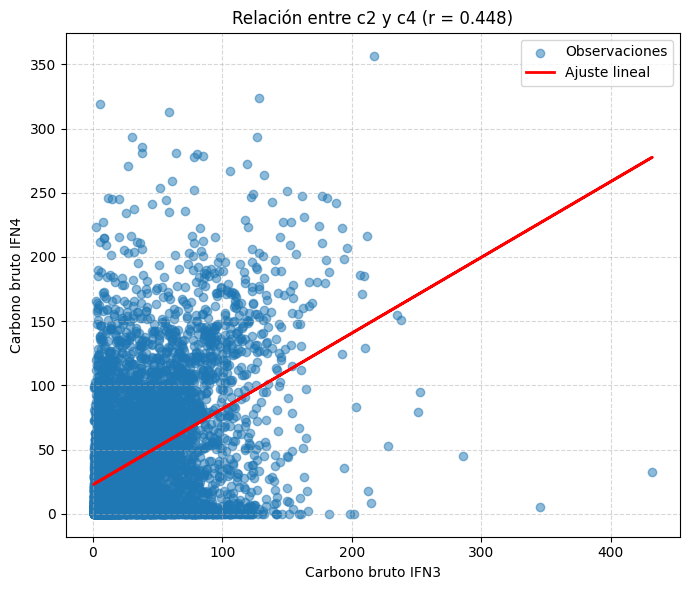

In [7]:
# -*- coding: utf-8 -*-
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

# === 1) Cargar los datos ===
ruta = "bbdd/ifn2_ifn4.csv"
df = pd.read_csv(ruta)

# Verificar que las columnas existen
if not {'c2', 'c4'}.issubset(df.columns):
    raise KeyError("El archivo no contiene las columnas 'c2' y 'c4'.")

# Eliminar posibles NaN
df = df.dropna(subset=['c2', 'c4'])

# === 2) Calcular correlación y ajuste lineal ===
corr = df['c2'].corr(df['c4'])
slope, intercept, r_value, p_value, std_err = linregress(df['c2'], df['c4'])

print(f"Coeficiente de correlación (r): {corr:.4f}")
print(f"Ecuación de regresión: c4 = {intercept:.3f} + {slope:.3f} * c2")
print(f"R² (regresión): {r_value**2:.4f}")
print(f"p-valor: {p_value:.2e}")

# === 3) Gráfico de dispersión con línea de ajuste ===
plt.figure(figsize=(7,6))
plt.scatter(df['c2'], df['c4'], alpha=0.5, label='Observaciones')
plt.plot(df['c2'], intercept + slope * df['c2'], color='red', linewidth=2, label='Ajuste lineal')
plt.xlabel("Carbono bruto IFN3")
plt.ylabel("Carbono bruto IFN4")
plt.title(f"Relación entre c2 y c4 (r = {corr:.3f})")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


IFN4: bruto versus normal

/tmp/ipykernel_3054068/2289420185.py:11: DtypeWarning: Columns (0: orientacion_cat, 1: pendiente_cat) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(ruta)


✅ CSV cargado: bbdd/ifn3_ifn4.csv
Filas totales: 119,864
✅ Filas válidas con ambas variables no nulas: 89,011

📊 Estadísticos descriptivos:
                 c4  carbono_bruto4
count  89011.000000    89011.000000
mean      24.451127       20.060288
std       42.033306       33.914311
min        0.000000        0.000327
25%        0.000000        0.012004
50%        7.164174        5.546166
75%       31.381713       24.272142
max      883.462735      420.464517

📈 Coeficiente de variación (CV):
c4                1.719074
carbono_bruto4    1.690619
dtype: float64

🔗 Correlación (Pearson) entre c4 y carbono_bruto4: 0.8794


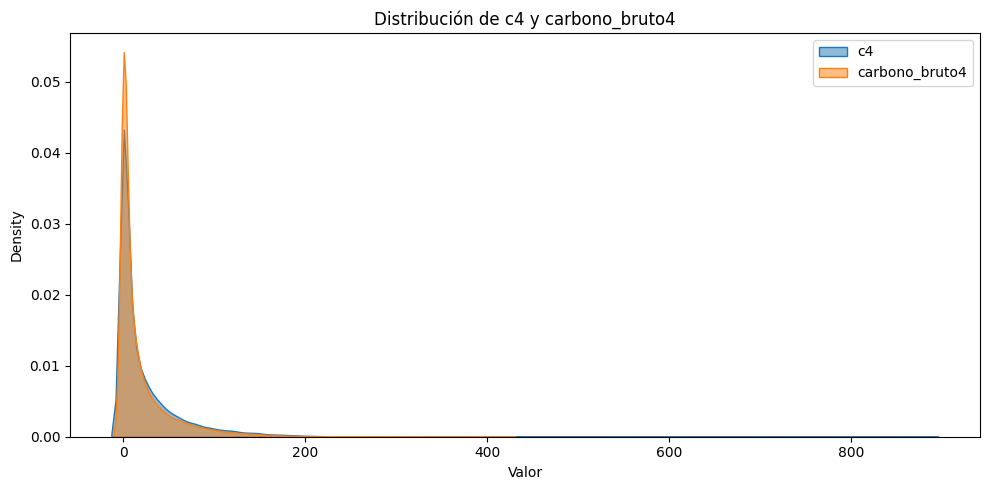

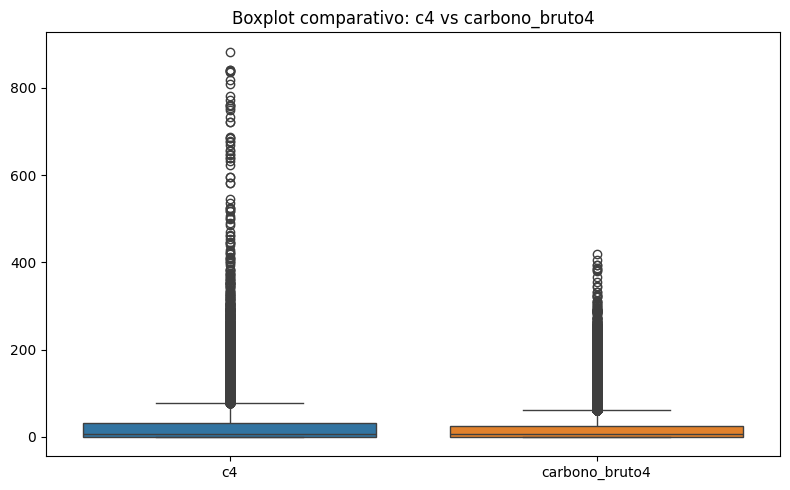

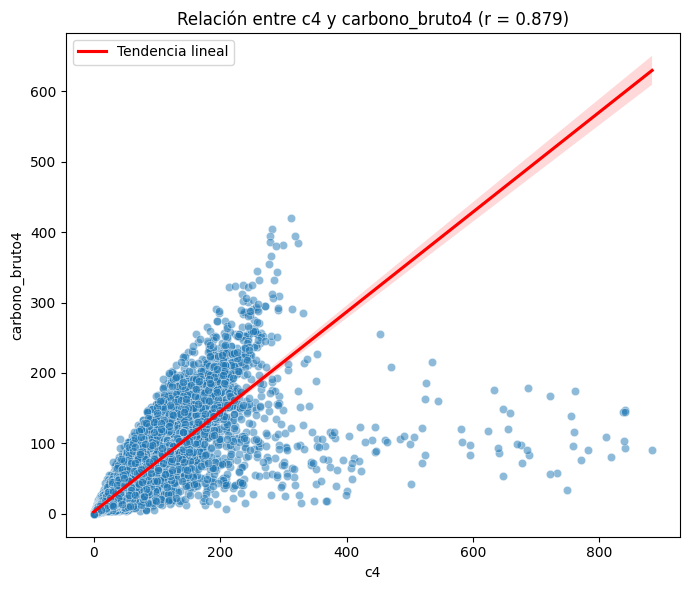


🚨 Posibles outliers detectados (|z|>3): 2,708 filas
Proporción: 3.04% del total


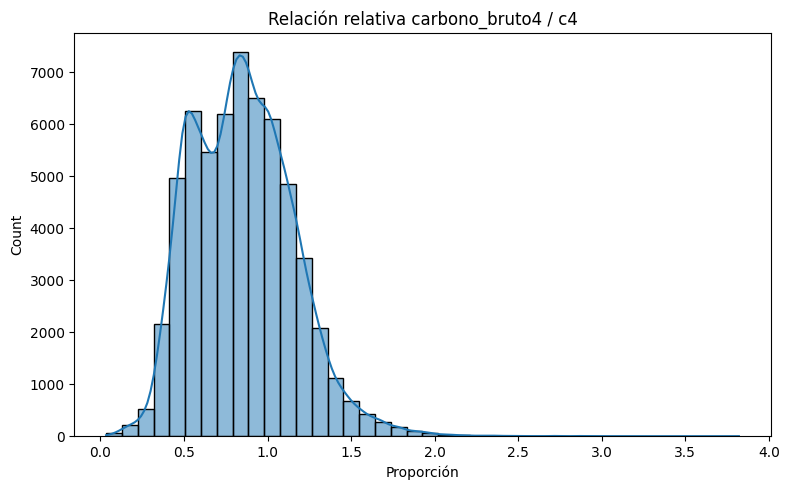


📈 Media de la relación carbono_bruto4 / c4: inf
📉 Desviación estándar: nan


<venv>/lib/python3.13/site-packages/pandas/core/nanops.py:1020: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


In [8]:
# -*- coding: utf-8 -*-
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# =========================
# 1️⃣ CARGA DE DATOS
# =========================
ruta = r"bbdd/ifn3_ifn4.csv"
df = pd.read_csv(ruta)

print(f"✅ CSV cargado: {ruta}")
print(f"Filas totales: {len(df):,}")

# Convertir columnas a numéricas (por seguridad)
for col in ["c4", "carbono_bruto4"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    else:
        raise ValueError(f"❌ Falta la columna '{col}' en el CSV.")

# Filtrar filas válidas (ambas no nulas)
df_valid = df.dropna(subset=["c4", "carbono_bruto4"]).copy()
print(f"✅ Filas válidas con ambas variables no nulas: {len(df_valid):,}")

# =========================
# 2️⃣ ESTADÍSTICOS BÁSICOS
# =========================
print("\n📊 Estadísticos descriptivos:")
print(df_valid[["c4", "carbono_bruto4"]].describe())

# Coeficiente de variación (CV = std / mean)
cv = df_valid[["c4", "carbono_bruto4"]].std() / df_valid[["c4", "carbono_bruto4"]].mean()
print("\n📈 Coeficiente de variación (CV):")
print(cv)

# =========================
# 3️⃣ CORRELACIÓN ENTRE AMBAS VARIABLES
# =========================
corr = df_valid["c4"].corr(df_valid["carbono_bruto4"])
print(f"\n🔗 Correlación (Pearson) entre c4 y carbono_bruto4: {corr:.4f}")

# =========================
# 4️⃣ GRÁFICOS
# =========================

# --- Histograma y densidad ---
plt.figure(figsize=(10,5))
sns.kdeplot(df_valid["c4"], label="c4", fill=True, alpha=0.5)
sns.kdeplot(df_valid["carbono_bruto4"], label="carbono_bruto4", fill=True, alpha=0.5)
plt.title("Distribución de c4 y carbono_bruto4")
plt.xlabel("Valor")
plt.legend()
plt.tight_layout()
plt.show()

# --- Boxplots comparativos ---
plt.figure(figsize=(8,5))
sns.boxplot(data=df_valid[["c4", "carbono_bruto4"]])
plt.title("Boxplot comparativo: c4 vs carbono_bruto4")
plt.tight_layout()
plt.show()

# --- Scatter plot ---
plt.figure(figsize=(7,6))
sns.scatterplot(x="c4", y="carbono_bruto4", data=df_valid, alpha=0.5)
sns.regplot(x="c4", y="carbono_bruto4", data=df_valid, scatter=False, color="red", label="Tendencia lineal")
plt.title(f"Relación entre c4 y carbono_bruto4 (r = {corr:.3f})")
plt.legend()
plt.tight_layout()
plt.show()

# =========================
# 5️⃣ DETECCIÓN SIMPLE DE OUTLIERS
# =========================
from scipy.stats import zscore

df_z = df_valid[["c4", "carbono_bruto4"]].apply(zscore)
outliers = ((df_z.abs() > 3).any(axis=1)).sum()

print(f"\n🚨 Posibles outliers detectados (|z|>3): {outliers:,} filas")
print(f"Proporción: {100*outliers/len(df_valid):.2f}% del total")

# =========================
# 6️⃣ RELACIÓN RELATIVA
# =========================
df_valid["relacion"] = df_valid["carbono_bruto4"] / df_valid["c4"]
plt.figure(figsize=(8,5))
sns.histplot(df_valid["relacion"], bins=40, kde=True)
plt.title("Relación relativa carbono_bruto4 / c4")
plt.xlabel("Proporción")
plt.tight_layout()
plt.show()

print("\n📈 Media de la relación carbono_bruto4 / c4:", df_valid["relacion"].mean())
print("📉 Desviación estándar:", df_valid["relacion"].std())


IFN3-IFN4: correlaciones entre periodo y diferencias

In [9]:
# -*- coding: utf-8 -*-
import pandas as pd
from scipy.stats import pearsonr, spearmanr

# === Cargar datos ===
ruta = "bbdd/ifn3_ifn4.csv"
df = pd.read_csv(ruta)

# === Limpiar y asegurar tipos numéricos ===
df = df.dropna(subset=["periodo", "carbono_bruto3", "carbono_bruto4"])
df["periodo"] = df["periodo"].astype(float)

# === Calcular las diferencias ===
df["dif_c4_c3"] = df["carbono_bruto4"] - df["carbono_bruto3"]
df["dif_abs_c4_c3"] = (df["carbono_bruto4"] - df["carbono_bruto3"]).abs()

# === Función auxiliar para correlaciones ===
def corr_info(x, y):
    mask = x.notna() & y.notna()
    if mask.sum() < 2:
        return None
    r_pear, p_pear = pearsonr(x[mask], y[mask])
    r_spear, p_spear = spearmanr(x[mask], y[mask])
    return r_pear, p_pear, r_spear, p_spear

# === Correlaciones solicitadas ===
r1 = corr_info(df["periodo"], df["dif_c4_c3"])
r2 = corr_info(df["periodo"], df["dif_abs_c4_c3"])

# === Mostrar resultados ===
print("=== CORRELACIONES ENTRE PERIODO Y DIFERENCIAS ===")

if r1:
    print(f"periodo ↔ (carbono_bruto4 - carbono_bruto3):")
    print(f"  Pearson r = {r1[0]:.4f} (p = {r1[1]:.3g})")
    print(f"  Spearman ρ = {r1[2]:.4f} (p = {r1[3]:.3g})")

if r2:
    print(f"\nperiodo ↔ |carbono_bruto4 - carbono_bruto3|:")
    print(f"  Pearson r = {r2[0]:.4f} (p = {r2[1]:.3g})")
    print(f"  Spearman ρ = {r2[2]:.4f} (p = {r2[3]:.3g})")


=== CORRELACIONES ENTRE PERIODO Y DIFERENCIAS ===
periodo ↔ (carbono_bruto4 - carbono_bruto3):
  Pearson r = -0.0126 (p = 0.000225)
  Spearman ρ = 0.0040 (p = 0.245)

periodo ↔ |carbono_bruto4 - carbono_bruto3|:
  Pearson r = -0.0854 (p = 3.77e-138)
  Spearman ρ = -0.0491 (p = 8.8e-47)


/tmp/ipykernel_3054068/2583578149.py:7: DtypeWarning: Columns (0: orientacion_cat, 1: pendiente_cat) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(ruta)


IFN2-IFN4: correlaciones entre periodo y diferencias

In [10]:
# -*- coding: utf-8 -*-
import pandas as pd
from scipy.stats import pearsonr, spearmanr

# === Cargar datos ===
ruta = "bbdd/ifn2_ifn4.csv"
df = pd.read_csv(ruta)

# === Filtros opcionales (mismos criterios usados antes) ===

# === Limpiar y asegurar tipos numéricos ===
df = df.dropna(subset=["periodo", "carbono_bruto2", "carbono_bruto4"])
df["periodo"] = df["periodo"].astype(float)

# === Calcular las diferencias ===
df["dif_c4_c3"] = df["carbono_bruto4"] - df["carbono_bruto2"]
df["dif_abs_c4_c3"] = (df["carbono_bruto4"] - df["carbono_bruto2"]).abs()

# === Función auxiliar para correlaciones ===
def corr_info(x, y):
    mask = x.notna() & y.notna()
    if mask.sum() < 2:
        return None
    r_pear, p_pear = pearsonr(x[mask], y[mask])
    r_spear, p_spear = spearmanr(x[mask], y[mask])
    return r_pear, p_pear, r_spear, p_spear

# === Correlaciones solicitadas ===
r1 = corr_info(df["periodo"], df["dif_c4_c3"])
r2 = corr_info(df["periodo"], df["dif_abs_c4_c3"])

# === Mostrar resultados ===
print("=== CORRELACIONES ENTRE PERIODO Y DIFERENCIAS ===")

if r1:
    print(f"periodo ↔ (carbono_bruto4 - carbono_bruto2):")
    print(f"  Pearson r = {r1[0]:.4f} (p = {r1[1]:.3g})")
    print(f"  Spearman ρ = {r1[2]:.4f} (p = {r1[3]:.3g})")

if r2:
    print(f"\nperiodo ↔ |carbono_bruto4 - carbono_bruto2|:")
    print(f"  Pearson r = {r2[0]:.4f} (p = {r2[1]:.3g})")
    print(f"  Spearman ρ = {r2[2]:.4f} (p = {r2[3]:.3g})")


=== CORRELACIONES ENTRE PERIODO Y DIFERENCIAS ===
periodo ↔ (carbono_bruto4 - carbono_bruto2):
  Pearson r = 0.0427 (p = 0.000194)
  Spearman ρ = 0.1199 (p = 8.22e-26)

periodo ↔ |carbono_bruto4 - carbono_bruto2|:
  Pearson r = -0.2183 (p = 6.28e-83)
  Spearman ρ = -0.2452 (p = 8.28e-105)


-------------------------
CORRELACIONES

IFN3-IFN4: correlaciones

/tmp/ipykernel_3054068/4282128887.py:9: DtypeWarning: Columns (0: orientacion_cat, 1: pendiente_cat) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("bbdd/ifn3_ifn4.csv")


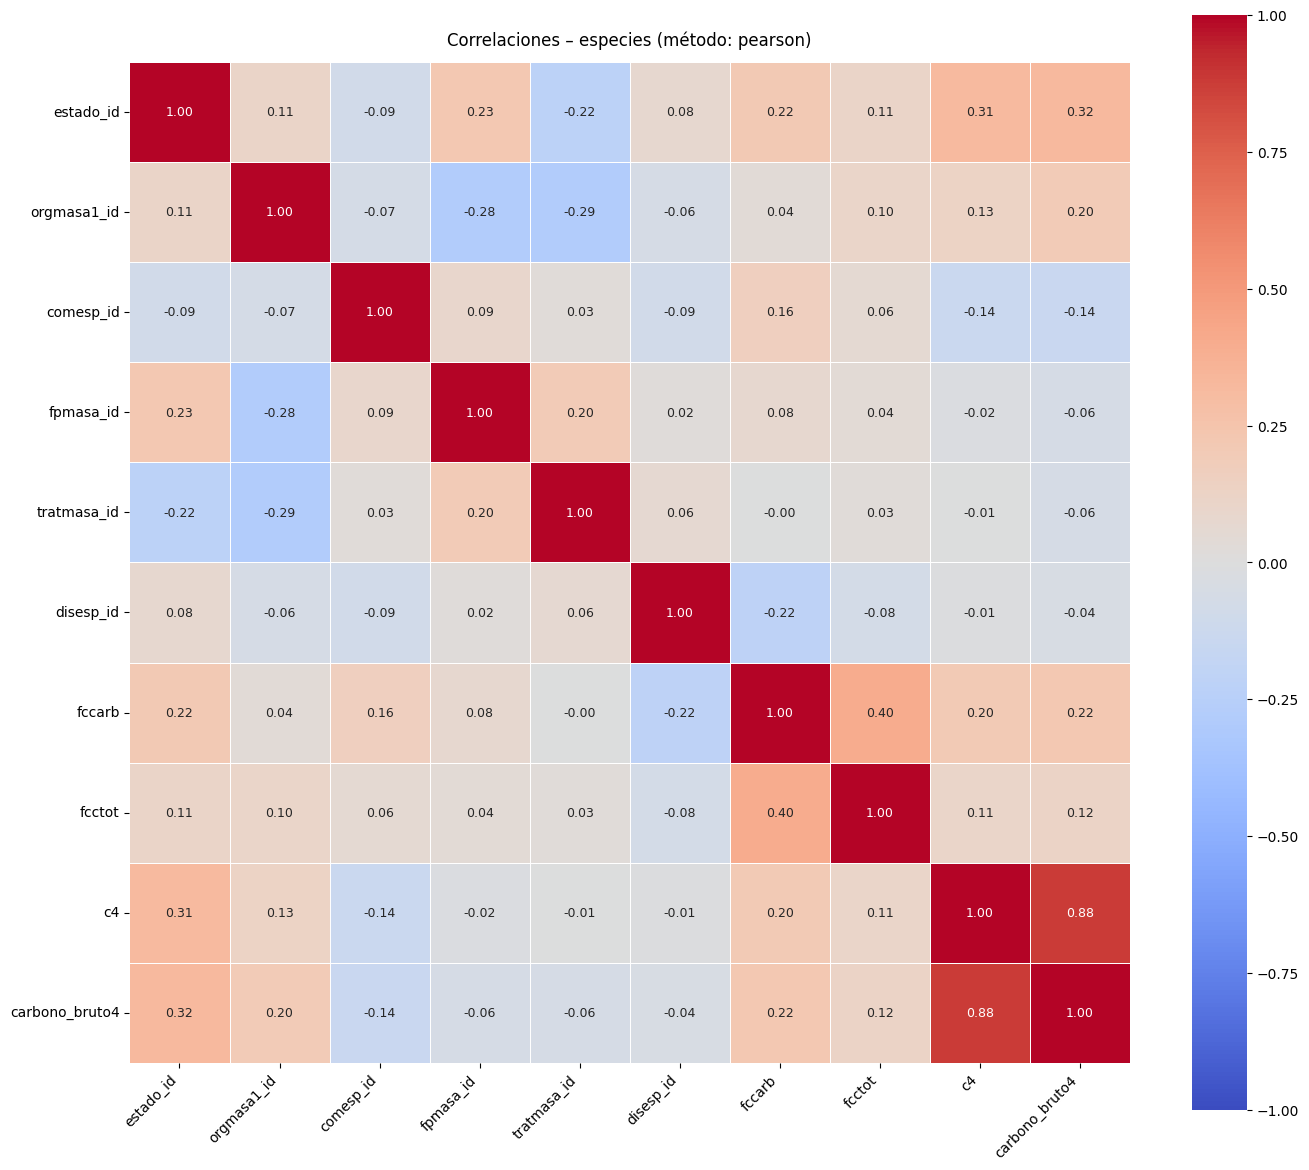

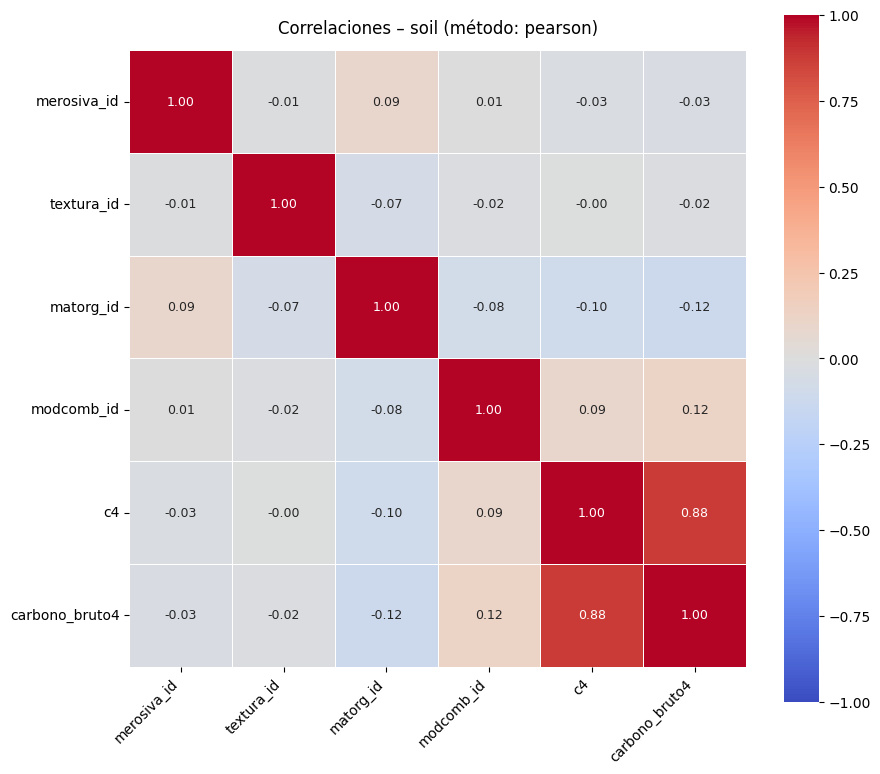

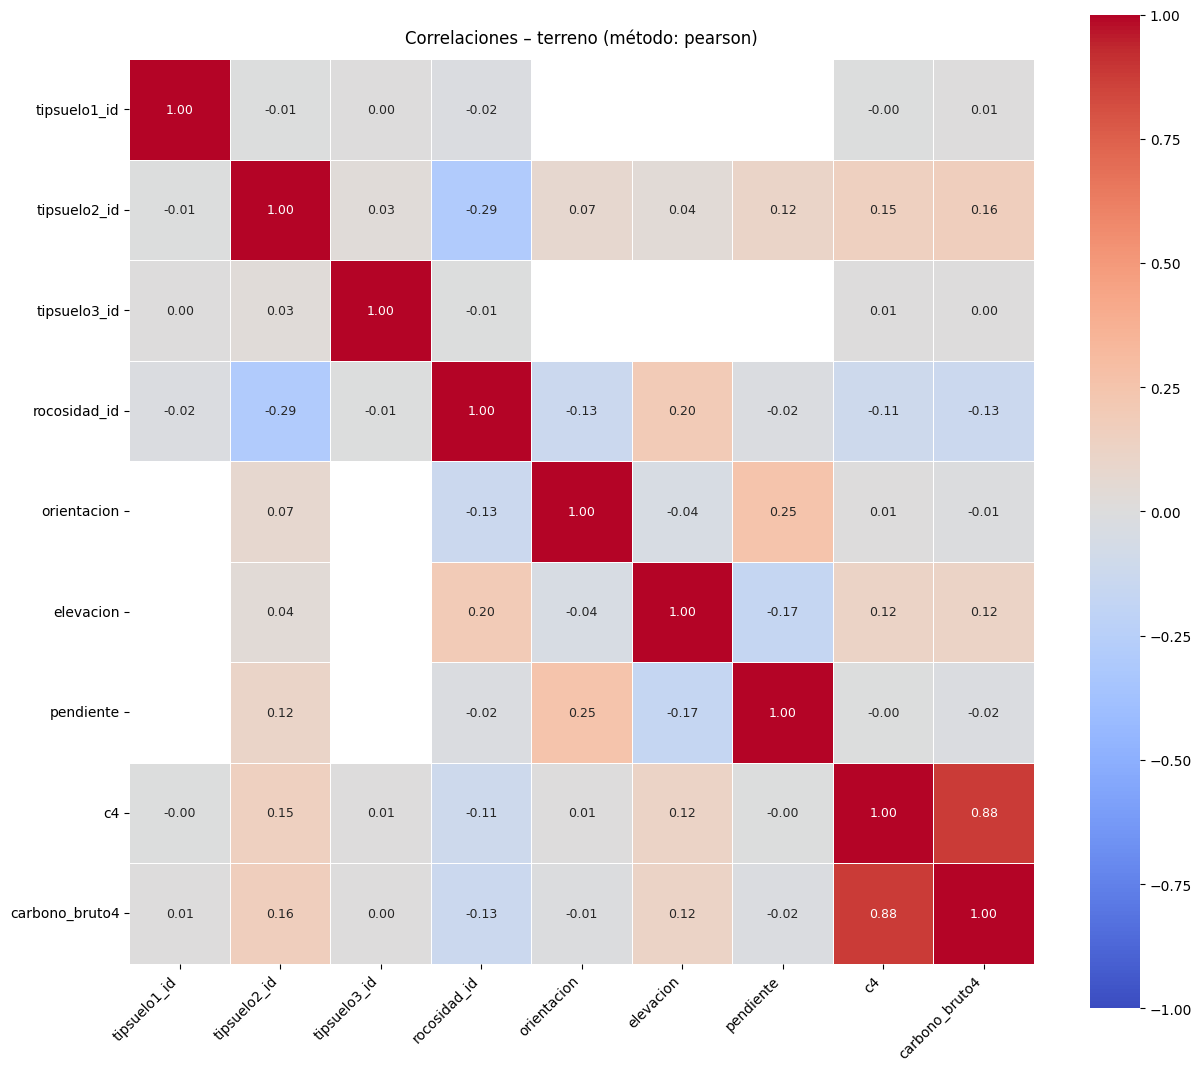

⚠️  Correlaciones – temperaturas_y_precipitaciones: se omiten por no existir -> ['pr_sum_invierno', 'pr_sum_otoño', 'pr_sum_primavera', 'pr_sum_verano', 'skt_mean_primavera', 'skt_mean_verano', 'skt_std_primavera', 'skt_std_verano']


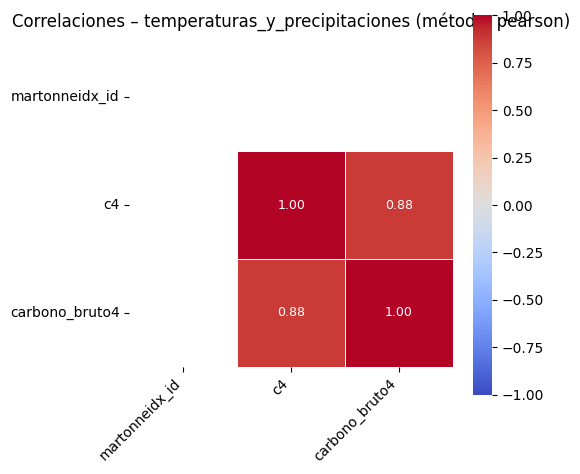

⚠️  Correlaciones – indices: se omiten por no existir -> ['gndvi_std_verano', 'ndii_mean_verano', 'ndii_std_primavera']


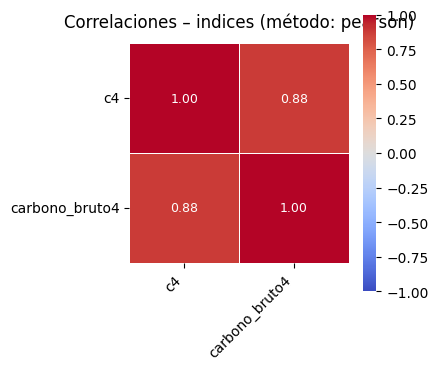

In [11]:
# ================= Heatmaps de correlaciones por bloque =================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------------------------------------------------
# 1) Usa tu DataFrame existente 'df'. Si no, descomenta la línea de carga:
df = pd.read_csv("bbdd/ifn3_ifn4.csv")
# -----------------------------------------------------------------------

# ---- Definición de bloques (corrijo comillas y espacios) ---------------
blocks = {
    "especies": [
        "estado_id","orgmasa1_id","comesp_id","fpmasa_id","tratmasa_id",
        "disesp_id","fccarb","fcctot",'c4', 'carbono_bruto4'
    ],
    "soil": ["merosiva_id","textura_id","matorg_id","modcomb_id",'c4', 'carbono_bruto4'],
    "terreno": ["tipsuelo1_id","tipsuelo2_id","tipsuelo3_id","rocosidad_id","orientacion","elevacion","pendiente",'c4', 'carbono_bruto4'],
    
    "temperaturas_y_precipitaciones": [
        "skt_mean_primavera","skt_mean_verano","skt_std_primavera","skt_std_verano",
        "pr_sum_invierno","pr_sum_otoño","pr_sum_primavera","pr_sum_verano","martonneidx_id",'c4', 'carbono_bruto4'
    ],
    "indices": ["gndvi_std_verano","ndii_mean_verano","ndii_std_primavera",'c4', 'carbono_bruto4'],
}

# --- Configuración del cálculo/plot ---
corr_method = "pearson"   # 'pearson' | 'spearman' (spearman es robusta a no linealidad)
annot_fmt   = ".2f"       # formato de número en las celdas
cmap        = "coolwarm"  # paleta

# --- Función de ayuda para ploteo por bloque ---
def plot_block_corr(df, cols, title, method="pearson"):
    # Filtra columnas presentes
    present = [c for c in cols if c in df.columns]
    missing = sorted(set(cols) - set(present))
    if missing:
        print(f"⚠️  {title}: se omiten por no existir -> {missing}")

    # Si quedan menos de 2, no tiene sentido una correlación
    if len(present) < 2:
        print(f"ℹ️  {title}: <2 columnas presentes ({present}). No se dibuja heatmap.")
        return

    # Fuerza numérico (coerce) por si hay objetos/categorías; rellena NA si fuera necesario
    df_num = df[present].apply(pd.to_numeric, errors="coerce")
    # Si todas NA en alguna columna, la correlación será NaN; se permite.
    corr = df_num.corr(method=method)

    # Plot
    plt.figure(figsize=(1.2*len(present)+2, 1.0*len(present)+2))
    sns.heatmap(
        corr, vmin=-1, vmax=1, cmap=cmap, square=True,
        annot=True, fmt=annot_fmt, linewidths=0.5, cbar=True,
        annot_kws={"size": 9}
    )
    plt.title(f"{title} (método: {method})", fontsize=12, pad=12)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

# --- Ejecuta para cada bloque ---
for name, cols in blocks.items():
    plot_block_corr(df, cols, title=f"Correlaciones – {name}", method=corr_method)


In [12]:
# -*- coding: utf-8 -*-
# Analiza correlaciones por bloques y muestra heatmaps con valores en pantalla

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------
# Configuración
# ----------------------------
CSV_PATH = "bbdd/ifn3_ifn4.csv"     # Ajusta la ruta si es distinta
THRESHOLD = 0.70                    # Umbral de correlación (valor absoluto)
INCLUDE_TARGETS = ['carbono_bruto4', 'c4']

# ----------------------------
# Cargar datos
# ----------------------------
df = pd.read_csv(CSV_PATH)

# ----------------------------
# Definir bloques de variables
# ----------------------------
bloque_temp = [
    'skt_max_invierno','skt_max_otoño','skt_max_primavera','skt_max_verano',
    'skt_mean_invierno','skt_mean_otoño','skt_mean_primavera','skt_mean_verano',
    'skt_min_invierno','skt_min_otoño','skt_min_primavera','skt_min_verano',
    'skt_std_invierno','skt_std_otoño','skt_std_primavera','skt_std_verano',
    'stl1_max_invierno','stl1_max_otoño','stl1_max_primavera','stl1_max_verano',
    'stl1_mean_invierno','stl1_mean_otoño','stl1_mean_primavera','stl1_mean_verano',
    'stl1_min_invierno','stl1_min_otoño','stl1_min_primavera','stl1_min_verano',
    'stl1_std_invierno','stl1_std_otoño','stl1_std_primavera','stl1_std_verano',
    'stl2_max_invierno','stl2_max_otoño','stl2_max_primavera','stl2_max_verano',
    'stl2_mean_invierno','stl2_mean_otoño','stl2_mean_primavera','stl2_mean_verano',
    'stl2_min_invierno','stl2_min_otoño','stl2_min_primavera','stl2_min_verano',
    'stl2_std_invierno','stl2_std_otoño','stl2_std_primavera','stl2_std_verano',
    'stl3_max_invierno','stl3_max_otoño','stl3_max_primavera','stl3_max_verano',
    'stl3_mean_invierno','stl3_mean_otoño','stl3_mean_primavera','stl3_mean_verano',
    'stl3_min_invierno','stl3_min_otoño','stl3_min_primavera','stl3_min_verano',
    'stl3_std_invierno','stl3_std_otoño','stl3_std_primavera','stl3_std_verano',
    'stl4_max_invierno','stl4_max_otoño','stl4_max_primavera','stl4_max_verano',
    'stl4_mean_invierno','stl4_mean_otoño','stl4_mean_primavera','stl4_mean_verano',
    'stl4_min_invierno','stl4_min_otoño','stl4_min_primavera','stl4_min_verano',
    'stl4_std_invierno','stl4_std_otoño','stl4_std_primavera','stl4_std_verano',
    't2m_max_invierno','t2m_max_otoño','t2m_max_primavera','t2m_max_verano',
    't2m_mean_invierno','t2m_mean_otoño','t2m_mean_primavera','t2m_mean_verano',
    't2m_min_invierno','t2m_min_otoño','t2m_min_primavera','t2m_min_verano',
    't2m_std_invierno','t2m_std_otoño','t2m_std_primavera','t2m_std_verano'
]

bloque_pr = [
    'pr_max_invierno','pr_max_otoño','pr_max_primavera','pr_max_verano',
    'pr_mean_invierno','pr_mean_otoño','pr_mean_primavera','pr_mean_verano',
    'pr_min_invierno','pr_min_otoño','pr_min_primavera','pr_min_verano',
    'pr_std_invierno','pr_std_otoño','pr_std_primavera','pr_std_verano',
    'pr_sum_invierno','pr_sum_otoño','pr_sum_primavera','pr_sum_verano'
]

bloque_veg = [
    'evi_max_invierno','evi_max_otoño','evi_max_primavera','evi_max_verano',
    'evi_mean_invierno','evi_mean_otoño','evi_mean_primavera','evi_mean_verano',
    'evi_median_invierno','evi_median_otoño','evi_median_primavera','evi_median_verano',
    'evi_min_invierno','evi_min_otoño','evi_min_primavera','evi_min_verano',
    'evi_std_invierno','evi_std_otoño','evi_std_primavera','evi_std_verano',
    'gndvi_max_invierno','gndvi_max_otoño','gndvi_max_primavera','gndvi_max_verano',
    'gndvi_mean_invierno','gndvi_mean_otoño','gndvi_mean_primavera','gndvi_mean_verano',
    'gndvi_median_invierno','gndvi_median_otoño','gndvi_median_primavera','gndvi_median_verano',
    'gndvi_min_invierno','gndvi_min_otoño','gndvi_min_primavera','gndvi_min_verano',
    'gndvi_std_invierno','gndvi_std_otoño','gndvi_std_primavera','gndvi_std_verano',
    'ndii_max_invierno','ndii_max_otoño','ndii_max_primavera','ndii_max_verano',
    'ndii_mean_invierno','ndii_mean_otoño','ndii_mean_primavera','ndii_mean_verano',
    'ndii_median_invierno','ndii_median_otoño','ndii_median_primavera','ndii_median_verano',
    'ndii_min_invierno','ndii_min_otoño','ndii_min_primavera','ndii_min_verano',
    'ndii_std_invierno','ndii_std_otoño','ndii_std_primavera','ndii_std_verano',
    'ndvi_max_invierno','ndvi_max_otoño','ndvi_max_primavera','ndvi_max_verano',
    'ndvi_mean_invierno','ndvi_mean_otoño','ndvi_mean_primavera','ndvi_mean_verano',
    'ndvi_median_invierno','ndvi_median_otoño','ndvi_median_primavera','ndvi_median_verano',
    'ndvi_min_invierno','ndvi_min_otoño','ndvi_min_primavera','ndvi_min_verano',
    'ndvi_std_invierno','ndvi_std_otoño','ndvi_std_primavera','ndvi_std_verano'
]

bloques = {
    'temperatura_suelo_aire': bloque_temp,
    'precipitacion': bloque_pr,
    'indices_vegetacion': bloque_veg
}

# ----------------------------
# Funciones auxiliares
# ----------------------------
def available(cols):
    """Devuelve columnas válidas (presentes y numéricas)."""
    keep = []
    for c in cols:
        if c in df.columns:
            if not pd.api.types.is_numeric_dtype(df[c]):
                df[c] = pd.to_numeric(df[c], errors='coerce')
            keep.append(c)
    return keep

def connected_components_from_corr(corr, thr):
    """Encuentra grupos de variables con |corr| ≥ thr."""
    vars_ = list(corr.columns)
    adj = {v: set() for v in vars_}
    for i, j in itertools.combinations(vars_, 2):
        val = corr.loc[i, j]
        if pd.notna(val) and abs(val) >= thr:
            adj[i].add(j)
            adj[j].add(i)

    visited = set()
    components = []
    for v in vars_:
        if v not in visited:
            stack = [v]
            comp = set()
            while stack:
                u = stack.pop()
                if u in visited:
                    continue
                visited.add(u)
                comp.add(u)
                for w in adj[u]:
                    if w not in visited:
                        stack.append(w)
            if len(comp) >= 2:
                components.append(sorted(list(comp)))
    return components

def plot_heatmap_with_numbers(corr_df, title):
    """Heatmap con valores numéricos en cada celda."""
    fig, ax = plt.subplots(figsize=(0.5*len(corr_df.columns)+4, 0.5*len(corr_df.columns)+3))
    im = ax.imshow(corr_df, vmin=-1, vmax=1, cmap='coolwarm')
    ax.set_xticks(np.arange(len(corr_df.columns)))
    ax.set_yticks(np.arange(len(corr_df.index)))
    ax.set_xticklabels(corr_df.columns, rotation=90)
    ax.set_yticklabels(corr_df.index)
    plt.title(title)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Agregar texto de correlaciones
    for i in range(len(corr_df.index)):
        for j in range(len(corr_df.columns)):
            val = corr_df.iloc[i, j]
            ax.text(j, i, f"{val:.2f}" if not np.isnan(val) else "", 
                    ha='center', va='center', color='black', fontsize=8)
    plt.tight_layout()
    plt.show()

# ----------------------------
# Ejecución
# ----------------------------
present_targets = [t for t in INCLUDE_TARGETS if t in df.columns]

for nombre_bloque, cols in bloques.items():
    cols_ok = available(cols)
    if len(cols_ok) < 2:
        print(f"[{nombre_bloque}] No hay suficientes columnas válidas.")
        continue

    corr_block = df[cols_ok].corr()
    comps = connected_components_from_corr(corr_block, THRESHOLD)

    if not comps:
        print(f"\n[{nombre_bloque}] No hay grupos con |r| ≥ {THRESHOLD}. Mostrando heatmap global.\n")
        subcols = cols_ok + [t for t in present_targets if t not in cols_ok]
        corr_sub = df[subcols].corr()
        plot_heatmap_with_numbers(corr_sub, f"{nombre_bloque} (global + targets)")
    else:
        print(f"\n[{nombre_bloque}] Grupos con |r| ≥ {THRESHOLD}:\n")
        for gi, comp in enumerate(comps, start=1):
            subcols = comp + [t for t in present_targets if t not in comp and t in df.columns]
            corr_sub = df[subcols].corr()
            print(f"Grupo {gi}: {', '.join(comp)}")
            plot_heatmap_with_numbers(corr_sub, f"{nombre_bloque} | grupo {gi} (|r|≥{THRESHOLD})")

print("\n✅ Análisis de correlaciones completado.")


[temperatura_suelo_aire] No hay suficientes columnas válidas.
[precipitacion] No hay suficientes columnas válidas.
[indices_vegetacion] No hay suficientes columnas válidas.

✅ Análisis de correlaciones completado.


/tmp/ipykernel_3054068/1458899104.py:19: DtypeWarning: Columns (0: orientacion_cat, 1: pendiente_cat) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(CSV_PATH)


In [13]:
# -*- coding: utf-8 -*-
# Muestra una matriz de correlación con valores en cada celda
# para tres bloques de variables: temperatura, precipitación y vegetación.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------
# Configuración
# ----------------------------
CSV_PATH = "bbdd/ifn3_ifn4.csv"   # ajusta si es necesario
INCLUDE_TARGETS = ['carbono_bruto4', 'c4']  # opcional: se añadirán si existen

# ----------------------------
# Cargar datos
# ----------------------------
df = pd.read_csv(CSV_PATH)

# ----------------------------
# Definir bloques
# ----------------------------
bloque_temp = [
    'skt_max_primavera','skt_max_verano',
    'skt_mean_primavera','skt_mean_verano',
    'skt_min_primavera','skt_min_verano',
    'skt_std_primavera','skt_std_verano'
]

bloque_pr = [
    'pr_sum_invierno','pr_sum_otoño','pr_sum_primavera','pr_sum_verano'
]

bloque_veg = [
  
    'evi_mean_primavera','evi_mean_verano'
    'evi_std_primavera','evi_std_verano',
    'gndvi_mean_primavera','gndvi_mean_verano',
    'gndvi_std_primavera','gndvi_std_verano',
    'ndii_mean_primavera','ndii_mean_verano',
    'ndii_std_primavera','ndii_std_verano'
]

bloques = {
    "Temperatura (skt)": bloque_temp,
    "Precipitación (pr_sum)": bloque_pr,
    "Vegetación (EVI, GNDVI, NDII)": bloque_veg
}

# ----------------------------
# Función para dibujar el heatmap con valores
# ----------------------------
def plot_heatmap_with_numbers(corr_df, title):
    fig, ax = plt.subplots(figsize=(0.5*len(corr_df.columns)+3, 0.5*len(corr_df.columns)+2))
    im = ax.imshow(corr_df, vmin=-1, vmax=1, cmap='coolwarm')
    ax.set_xticks(np.arange(len(corr_df.columns)))
    ax.set_yticks(np.arange(len(corr_df.index)))
    ax.set_xticklabels(corr_df.columns, rotation=90)
    ax.set_yticklabels(corr_df.index)
    plt.title(title)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Añadir valores numéricos en cada celda
    for i in range(len(corr_df.index)):
        for j in range(len(corr_df.columns)):
            val = corr_df.iloc[i, j]
            if not np.isnan(val):
                ax.text(j, i, f"{val:.2f}", ha='center', va='center', color='black', fontsize=8)
    plt.tight_layout()
    plt.show()

# ----------------------------
# Crear las matrices
# ----------------------------
for nombre_bloque, cols in bloques.items():
    # Filtrar columnas disponibles en el CSV
    disponibles = [c for c in cols if c in df.columns]
    if not disponibles:
        print(f"[{nombre_bloque}] ❌ Ninguna variable encontrada en el CSV.")
        continue

    # Añadir las variables objetivo si existen
    for target in INCLUDE_TARGETS:
        if target in df.columns and target not in disponibles:
            disponibles.append(target)

    # Calcular la matriz de correlación
    corr = df[disponibles].corr()

    print(f"\n📊 Matriz de correlación: {nombre_bloque}\n")
    display(corr)  # si estás en Jupyter, muestra la tabla
    plot_heatmap_with_numbers(corr, f"{nombre_bloque} (correlación)")


[Temperatura (skt)] ❌ Ninguna variable encontrada en el CSV.
[Precipitación (pr_sum)] ❌ Ninguna variable encontrada en el CSV.
[Vegetación (EVI, GNDVI, NDII)] ❌ Ninguna variable encontrada en el CSV.


/tmp/ipykernel_3054068/1468960805.py:18: DtypeWarning: Columns (0: orientacion_cat, 1: pendiente_cat) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(CSV_PATH)


IFN3 - IFN4:    ANOVA 

In [14]:
import os
if not os.path.exists("bbdd/ifn3_ifn4_entrenar_c.csv"):
    print("⚠️  bbdd/ifn3_ifn4_entrenar_c.csv no encontrado. Celda omitida.")
else:
    # ==================== ANOVA simplificado y robusto (target = c4) ====================
    import pandas as pd
    import numpy as np
    import statsmodels.api as sm
    from statsmodels.formula.api import ols
    from pathlib import Path
    
    # --- Cargar datos ---
    csv_path = Path("bbdd/ifn3_ifn4_entrenar_c.csv")
    df = pd.read_csv(csv_path)
    print(f"📂 Datos cargados: {df.shape[0]} filas, {df.shape[1]} columnas")
    
    # --- Definir variables categóricas ---
    base_cat_features = [
        'especie_id','tipo_especie','grupo_id','estado_id','fpmasa_id','tratmasa_id','orgmasa1_id',
        'tipsuelo1_id','tipsuelo2_id','tipsuelo3_id','rocosidad_id','nivel1_id','nivel2_id',
        'merosiva_id','textura_id','matorg_id','modcomb_id','disesp_id','comesp_id','orientacion_cat','pendiente_cat'
    ]
    
    target = 'c4'
    df = df.copy()
    
    # --- Limpiar variable objetivo ---
    df[target] = pd.to_numeric(df[target], errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan)
    df = df.dropna(subset=[target])
    print(f"✅ Filas válidas para '{target}': {len(df)}")
    
    # --- Ejecutar ANOVA ---
    results = []
    
    for cat in base_cat_features:
        if cat not in df.columns:
            print(f"⚠️  Variable no encontrada: {cat}")
            continue
        
        sub = df[[cat, target]].dropna()
        if sub[cat].nunique() < 2:
            print(f"⚠️  '{cat}' tiene solo una categoría, se omite.")
            continue
        
        # limitar número de niveles (si hay demasiados, reduce para evitar atasco)
        if sub[cat].nunique() > 100:
            top_cats = sub[cat].value_counts().nlargest(100).index
            sub = sub[sub[cat].isin(top_cats)]
            print(f"⚠️  '{cat}' tenía muchas categorías, se limitaron a las 100 más frecuentes.")
        
        try:
            model = ols(f"{target} ~ C({cat})", data=sub).fit()
            anova_table = sm.stats.anova_lm(model, typ=2)
            F = float(anova_table.loc[f"C({cat})", "F"])
            p = float(anova_table.loc[f"C({cat})", "PR(>F)"])
            results.append({"variable": cat, "F": F, "p_value": p})
        except Exception as e:
            print(f"❌ Error con {cat}: {e}")
    
    # --- Mostrar resultados ---
    if results:
        df_anova_c4 = pd.DataFrame(results).sort_values("p_value")
        print("\n📊 ANOVA resultados (target = c4):")
        display(df_anova_c4)
    else:
        print("❗No se generaron resultados válidos.")
    

/tmp/ipykernel_3054068/2156763027.py:14: DtypeWarning: Columns (0: orientacion_cat, 1: pendiente_cat) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path)


📂 Datos cargados: 48299 filas, 57 columnas
✅ Filas válidas para 'c4': 48299
⚠️  'especie_id' tenía muchas categorías, se limitaron a las 100 más frecuentes.


⚠️  'grupo_id' tiene solo una categoría, se omite.


⚠️  'nivel1_id' tiene solo una categoría, se omite.



📊 ANOVA resultados (target = c4):


,variable,F,p_value
0,especie_id,147.564968,0.000000e+00
2,estado_id,876.297758,0.000000e+00
14,modcomb_id,271.697587,0.000000e+00
16,comesp_id,717.730956,0.000000e+00
7,tipsuelo2_id,1105.237393,1.314314e-239
5,orgmasa1_id,480.686732,3.923122e-207
9,rocosidad_id,222.948611,5.725818e-190
13,matorg_id,370.724493,1.709420e-160
10,nivel2_id,69.354369,1.594169e-72
3,fpmasa_id,68.147146,5.916912e-44


In [15]:
import os
if not os.path.exists("bbdd/ifn3_ifn4_entrenar_carbono_bruto.csv"):
    print("⚠️  bbdd/ifn3_ifn4_entrenar_carbono_bruto.csv no encontrado. Celda omitida.")
else:
    # ==================== ANOVA simplificado y robusto (target = c4) ====================
    import pandas as pd
    import numpy as np
    import statsmodels.api as sm
    from statsmodels.formula.api import ols
    from pathlib import Path
    
    # --- Cargar datos ---
    csv_path = Path("bbdd/ifn3_ifn4_entrenar_carbono_bruto.csv")
    df = pd.read_csv(csv_path)
    print(f"📂 Datos cargados: {df.shape[0]} filas, {df.shape[1]} columnas")
    
    # --- Definir variables categóricas ---
    base_cat_features = [
        'especie_id','tipo_especie','grupo_id','estado_id','fpmasa_id','tratmasa_id','orgmasa1_id',
        'tipsuelo1_id','tipsuelo2_id','tipsuelo3_id','rocosidad_id','nivel1_id','nivel2_id',
        'merosiva_id','textura_id','matorg_id','modcomb_id','disesp_id','comesp_id','orientacion_cat','pendiente_cat'
    ]
    
    target = 'carbono_bruto4'
    df = df.copy()
    
    # --- Limpiar variable objetivo ---
    df[target] = pd.to_numeric(df[target], errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan)
    df = df.dropna(subset=[target])
    print(f"✅ Filas válidas para '{target}': {len(df)}")
    
    # --- Ejecutar ANOVA ---
    results = []
    
    for cat in base_cat_features:
        if cat not in df.columns:
            print(f"⚠️  Variable no encontrada: {cat}")
            continue
        
        sub = df[[cat, target]].dropna()
        if sub[cat].nunique() < 2:
            print(f"⚠️  '{cat}' tiene solo una categoría, se omite.")
            continue
        
        # limitar número de niveles (si hay demasiados, reduce para evitar atasco)
        if sub[cat].nunique() > 100:
            top_cats = sub[cat].value_counts().nlargest(100).index
            sub = sub[sub[cat].isin(top_cats)]
            print(f"⚠️  '{cat}' tenía muchas categorías, se limitaron a las 100 más frecuentes.")
        
        try:
            model = ols(f"{target} ~ C({cat})", data=sub).fit()
            anova_table = sm.stats.anova_lm(model, typ=2)
            F = float(anova_table.loc[f"C({cat})", "F"])
            p = float(anova_table.loc[f"C({cat})", "PR(>F)"])
            results.append({"variable": cat, "F": F, "p_value": p})
        except Exception as e:
            print(f"❌ Error con {cat}: {e}")
    
    # --- Mostrar resultados ---
    if results:
        df_anova_c4 = pd.DataFrame(results).sort_values("p_value")
        print("\n📊 ANOVA resultados (target = c4):")
        display(df_anova_c4)
    else:
        print("❗No se generaron resultados válidos.")
    

📂 Datos cargados: 62857 filas, 57 columnas
✅ Filas válidas para 'carbono_bruto4': 62857
⚠️  'especie_id' tenía muchas categorías, se limitaron a las 100 más frecuentes.


/tmp/ipykernel_3054068/3955432373.py:14: DtypeWarning: Columns (0: orientacion_cat, 1: pendiente_cat) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path)


⚠️  'grupo_id' tiene solo una categoría, se omite.


⚠️  'nivel1_id' tiene solo una categoría, se omite.



📊 ANOVA resultados (target = c4):


,variable,F,p_value
0,especie_id,414.838834,0.000000e+00
2,estado_id,1917.724636,0.000000e+00
7,tipsuelo2_id,1977.450342,0.000000e+00
5,orgmasa1_id,1701.688530,0.000000e+00
14,modcomb_id,347.701066,0.000000e+00
16,comesp_id,712.677070,0.000000e+00
9,rocosidad_id,351.801601,4.343938e-300
13,matorg_id,651.991979,5.926291e-281
3,fpmasa_id,208.150380,3.812198e-134
10,nivel2_id,95.637852,9.944802e-101


In [16]:
# ==================== Conteo de valores: nivel1_id y nivel2_id ====================
import pandas as pd

# Si aún no tienes el DataFrame cargado:
df = pd.read_csv("bbdd/ifn_entrenamiento.csv")

# Mostrar conteos y porcentajes
for col in ['nivel1_id', 'nivel2_id']:
    if col in df.columns:
        print(f"\n🔹 Distribución de '{col}':")
        conteo = df[col].value_counts(dropna=False).sort_index()
        porcentaje = (conteo / len(df) * 100).round(2)
        resumen = pd.DataFrame({'conteo': conteo, 'porcentaje (%)': porcentaje})
        display(resumen)
    else:
        print(f"⚠️ La columna '{col}' no está en el DataFrame.")



🔹 Distribución de 'nivel1_id':


/tmp/ipykernel_3054068/3053872891.py:5: DtypeWarning: Columns (0: orientacion_cat, 1: pendiente_cat) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("bbdd/ifn_entrenamiento.csv")


,conteo,porcentaje (%)
nivel1_id,,
1.0,119856,88.77
NaN,15168,11.23



🔹 Distribución de 'nivel2_id':


,conteo,porcentaje (%)
nivel2_id,,
1.0,111635,82.68
2.0,3887,2.88
3.0,467,0.35
4.0,45,0.03
6.0,3362,2.49
7.0,460,0.34
NaN,15168,11.23


----------------
IFN 2 - 3 - 4: correlaciones

/tmp/ipykernel_3054068/2933421078.py:9: DtypeWarning: Columns (0: orientacion_cat, 1: pendiente_cat) have mixed types. Specify dtype option on import or set low_memory=False.
  df_base = pd.read_csv("bbdd/ifn_entrenamiento.csv")


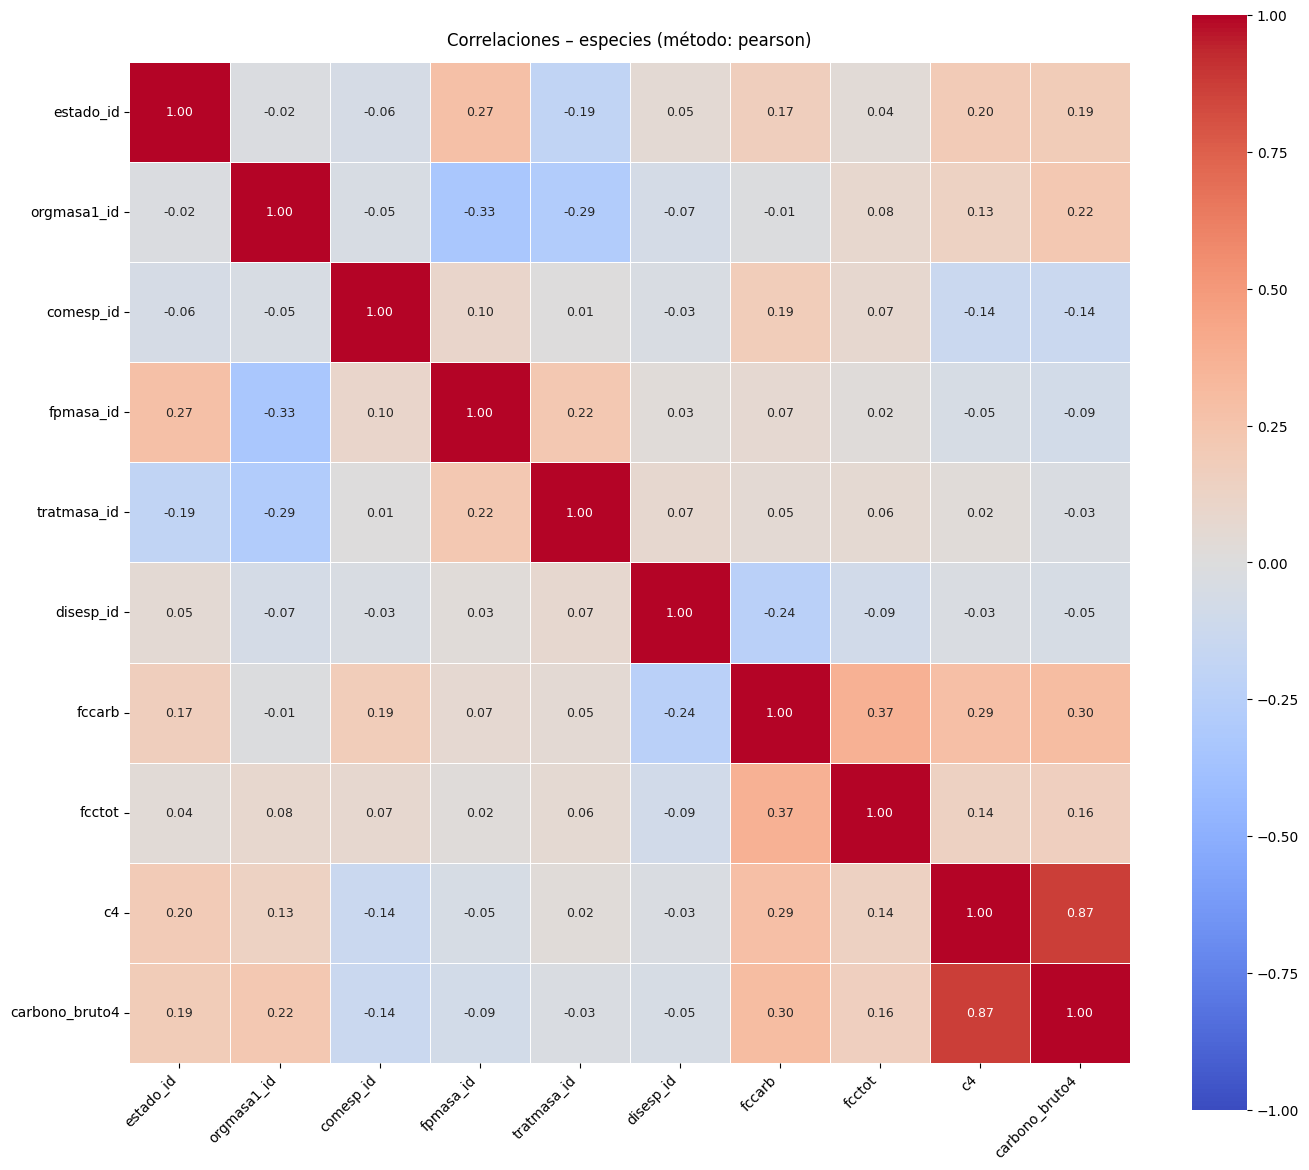

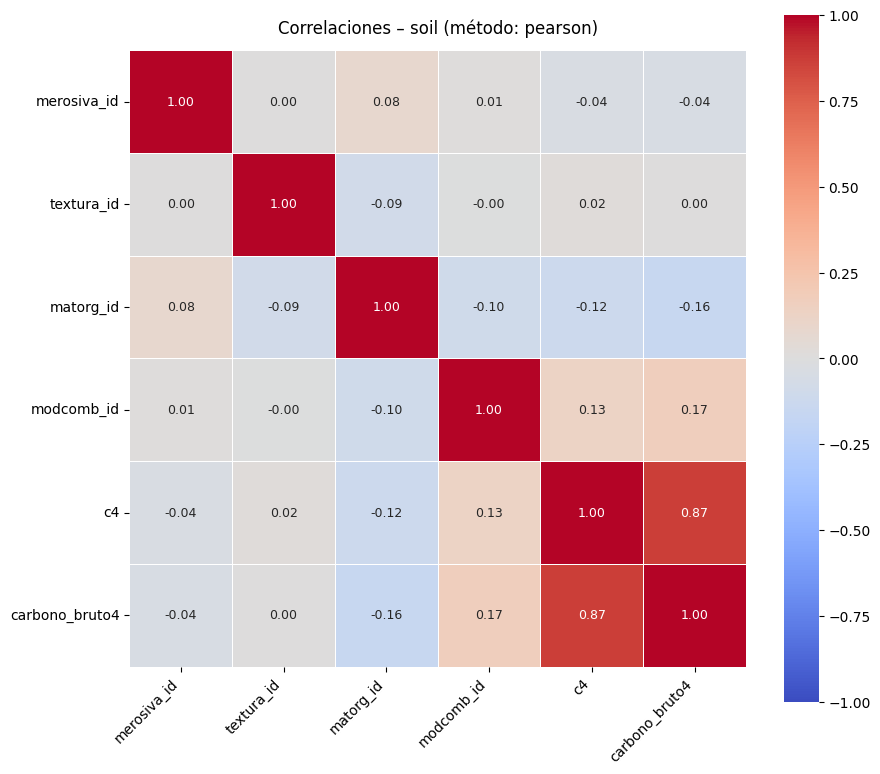

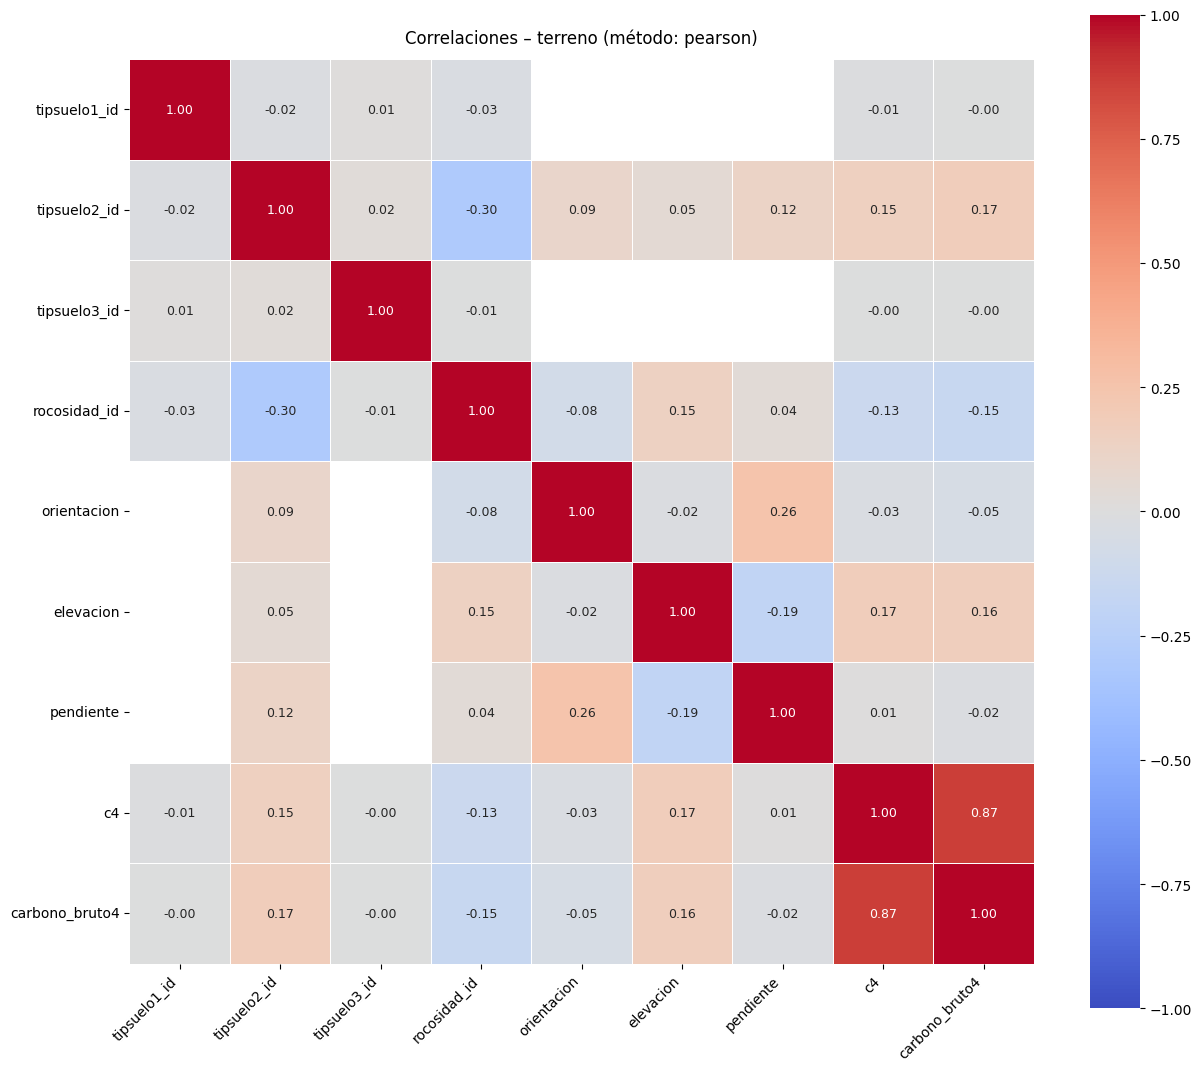

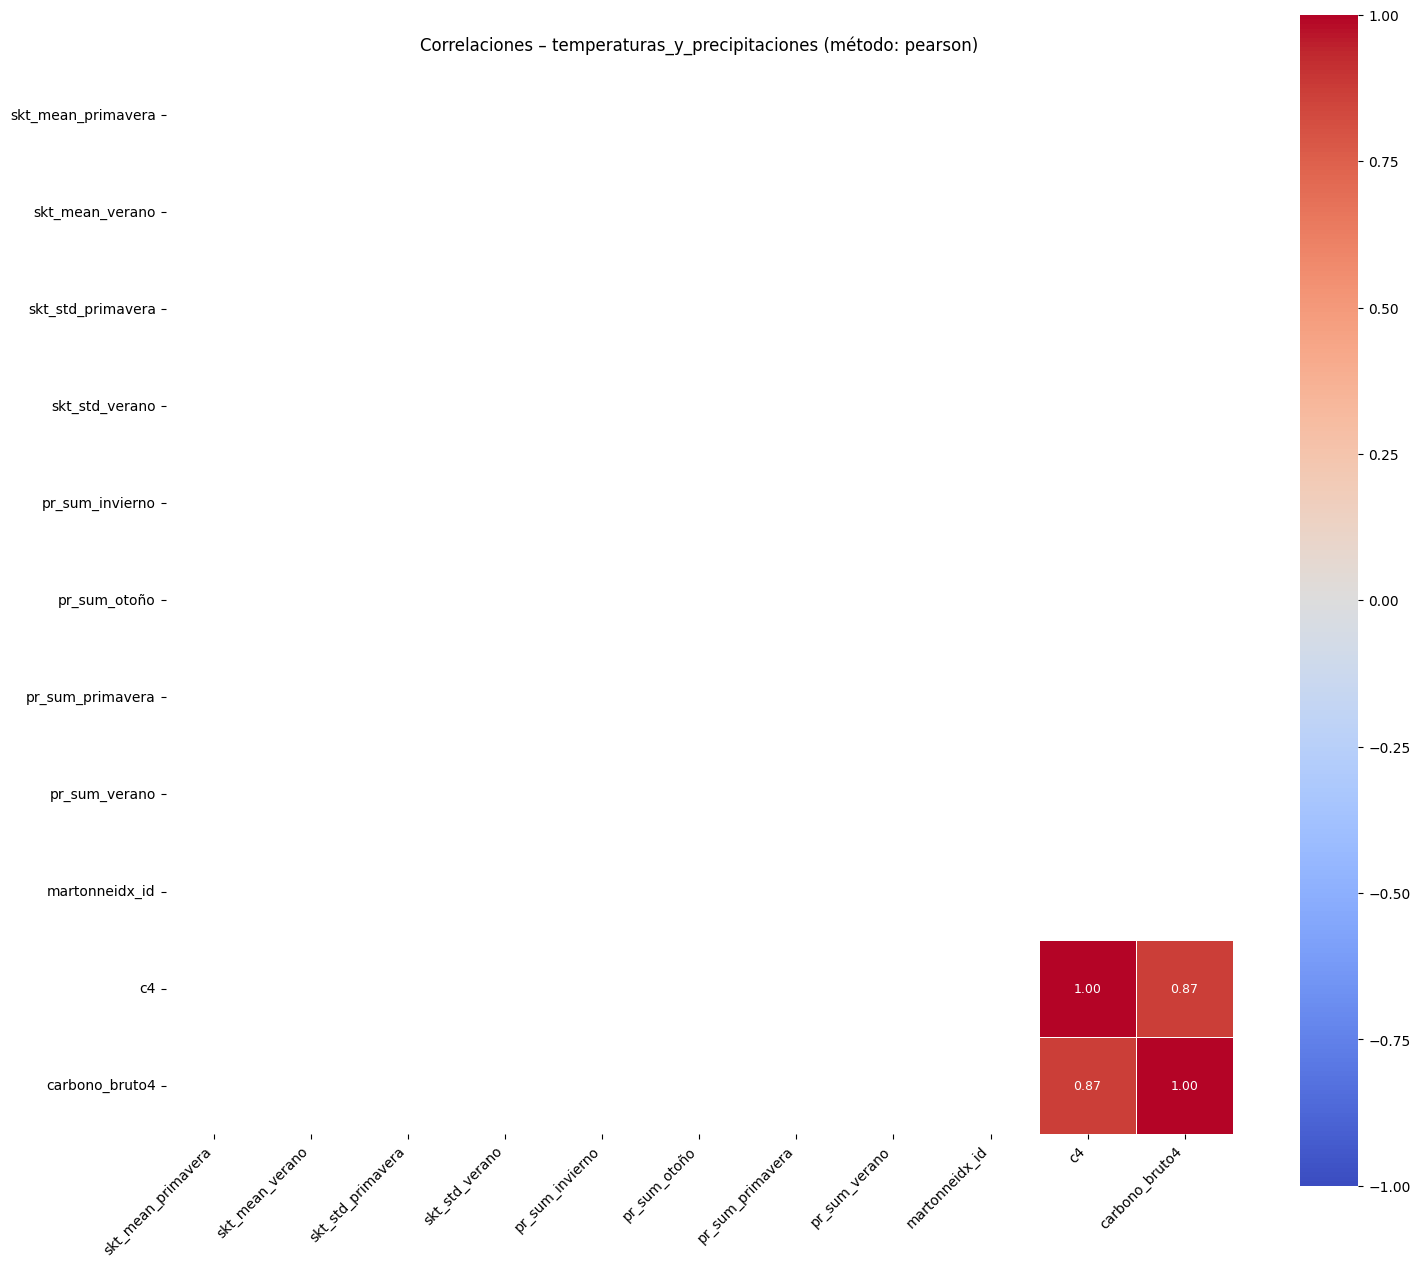

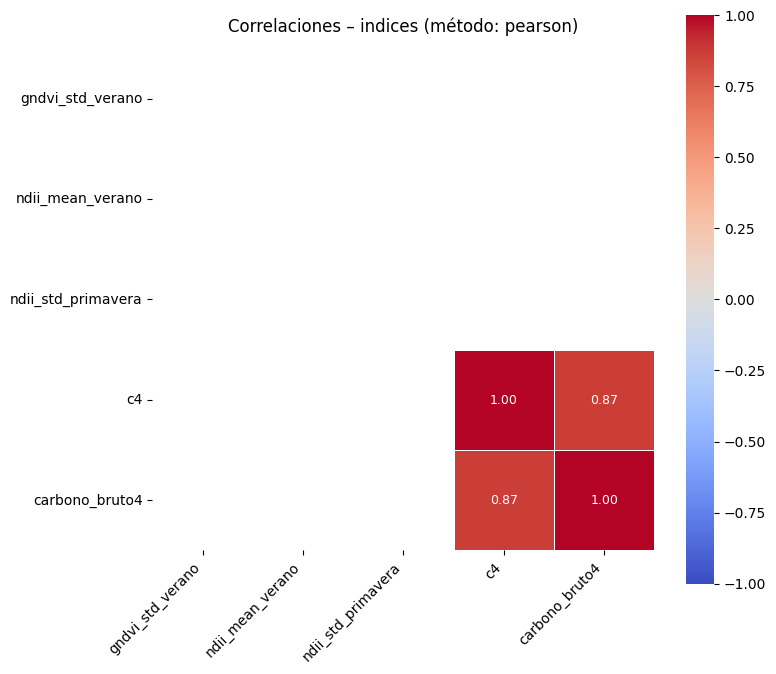

In [17]:
# ================= Heatmaps de correlaciones por bloque =================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------------------------------------------------
# 1) Usa tu DataFrame existente 'df'. Si no, descomenta la línea de carga:
df_base = pd.read_csv("bbdd/ifn_entrenamiento.csv")
df = df_base[(df_base['c4'].notna()) & (df_base['c4'] != 0) & ((df_base['c'].isna()) | (df_base['c'] < df_base['c4']))].copy()
# -----------------------------------------------------------------------

# ---- Definición de bloques (corrijo comillas y espacios) ---------------
blocks = {
    "especies": [
        "estado_id","orgmasa1_id","comesp_id","fpmasa_id","tratmasa_id",
        "disesp_id","fccarb","fcctot",'c4', 'carbono_bruto4'
    ],
    "soil": ["merosiva_id","textura_id","matorg_id","modcomb_id",'c4', 'carbono_bruto4'],
    "terreno": ["tipsuelo1_id","tipsuelo2_id","tipsuelo3_id","rocosidad_id","orientacion","elevacion","pendiente",'c4', 'carbono_bruto4'],
    
    "temperaturas_y_precipitaciones": [
        "skt_mean_primavera","skt_mean_verano","skt_std_primavera","skt_std_verano",
        "pr_sum_invierno","pr_sum_otoño","pr_sum_primavera","pr_sum_verano","martonneidx_id",'c4', 'carbono_bruto4'
    ],
    "indices": ["gndvi_std_verano","ndii_mean_verano","ndii_std_primavera",'c4', 'carbono_bruto4'],
}

# --- Configuración del cálculo/plot ---
corr_method = "pearson"   # 'pearson' | 'spearman' (spearman es robusta a no linealidad)
annot_fmt   = ".2f"       # formato de número en las celdas
cmap        = "coolwarm"  # paleta

# --- Función de ayuda para ploteo por bloque ---
def plot_block_corr(df, cols, title, method="pearson"):
    # Filtra columnas presentes
    present = [c for c in cols if c in df.columns]
    missing = sorted(set(cols) - set(present))
    if missing:
        print(f"⚠️  {title}: se omiten por no existir -> {missing}")

    # Si quedan menos de 2, no tiene sentido una correlación
    if len(present) < 2:
        print(f"ℹ️  {title}: <2 columnas presentes ({present}). No se dibuja heatmap.")
        return

    # Fuerza numérico (coerce) por si hay objetos/categorías; rellena NA si fuera necesario
    df_num = df[present].apply(pd.to_numeric, errors="coerce")
    # Si todas NA en alguna columna, la correlación será NaN; se permite.
    corr = df_num.corr(method=method)

    # Plot
    plt.figure(figsize=(1.2*len(present)+2, 1.0*len(present)+2))
    sns.heatmap(
        corr, vmin=-1, vmax=1, cmap=cmap, square=True,
        annot=True, fmt=annot_fmt, linewidths=0.5, cbar=True,
        annot_kws={"size": 9}
    )
    plt.title(f"{title} (método: {method})", fontsize=12, pad=12)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

# --- Ejecuta para cada bloque ---
for name, cols in blocks.items():
    plot_block_corr(df, cols, title=f"Correlaciones – {name}", method=corr_method)


-------------
IFN 2-3-4 : anova

In [18]:
# ==================== ANOVA simplificado y robusto (target = c4) ====================
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.formula.api import ols
from pathlib import Path

# --- Cargar datos ---

df_base = pd.read_csv("bbdd/ifn_entrenamiento.csv")
df = df_base[(df_base['c4'].notna()) & (df_base['c4'] != 0) & ((df_base['c'].isna()) | (df_base['c'] < df_base['c4']))].copy()
print(f"📂 Datos cargados: {df.shape[0]} filas, {df.shape[1]} columnas")

# --- Definir variables categóricas ---
base_cat_features = [
    'especie_id','tipo_especie','grupo_id','estado_id','fpmasa_id','tratmasa_id','orgmasa1_id',
    'tipsuelo1_id','tipsuelo2_id','tipsuelo3_id','rocosidad_id','nivel1_id','nivel2_id',
    'merosiva_id','textura_id','matorg_id','modcomb_id','disesp_id','comesp_id','orientacion_cat','pendiente_cat'
]

target = 'carbono_bruto4'
df = df.copy()

# --- Limpiar variable objetivo ---
df[target] = pd.to_numeric(df[target], errors="coerce")
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=[target])
print(f"✅ Filas válidas para '{target}': {len(df)}")

# --- Ejecutar ANOVA ---
results = []

for cat in base_cat_features:
    if cat not in df.columns:
        print(f"⚠️  Variable no encontrada: {cat}")
        continue
    
    sub = df[[cat, target]].dropna()
    if sub[cat].nunique() < 2:
        print(f"⚠️  '{cat}' tiene solo una categoría, se omite.")
        continue
    
    # limitar número de niveles (si hay demasiados, reduce para evitar atasco)
    if sub[cat].nunique() > 100:
        top_cats = sub[cat].value_counts().nlargest(100).index
        sub = sub[sub[cat].isin(top_cats)]
        print(f"⚠️  '{cat}' tenía muchas categorías, se limitaron a las 100 más frecuentes.")
    
    try:
        model = ols(f"{target} ~ C({cat})", data=sub).fit()
        anova_table = sm.stats.anova_lm(model, typ=2)
        F = float(anova_table.loc[f"C({cat})", "F"])
        p = float(anova_table.loc[f"C({cat})", "PR(>F)"])
        results.append({"variable": cat, "F": F, "p_value": p})
    except Exception as e:
        print(f"❌ Error con {cat}: {e}")

# --- Mostrar resultados ---
if results:
    df_anova_c4 = pd.DataFrame(results).sort_values("p_value")
    print("\n📊 ANOVA resultados (target = c4):")
    display(df_anova_c4)
else:
    print("❗No se generaron resultados válidos.")


/tmp/ipykernel_3054068/2415540938.py:10: DtypeWarning: Columns (0: orientacion_cat, 1: pendiente_cat) have mixed types. Specify dtype option on import or set low_memory=False.
  df_base = pd.read_csv("bbdd/ifn_entrenamiento.csv")


📂 Datos cargados: 55420 filas, 446 columnas
✅ Filas válidas para 'carbono_bruto4': 55420
⚠️  'especie_id' tenía muchas categorías, se limitaron a las 100 más frecuentes.


⚠️  'grupo_id' tiene solo una categoría, se omite.


⚠️  'nivel1_id' tiene solo una categoría, se omite.



📊 ANOVA resultados (target = c4):


,variable,F,p_value
0,especie_id,296.799414,0.000000e+00
2,estado_id,675.212847,0.000000e+00
7,tipsuelo2_id,1709.788734,0.000000e+00
5,orgmasa1_id,1234.117402,0.000000e+00
14,modcomb_id,328.835177,0.000000e+00
16,comesp_id,792.708146,0.000000e+00
9,rocosidad_id,352.612021,2.488611e-300
13,matorg_id,602.528672,3.719747e-259
15,disesp_id,174.546840,1.222788e-112
3,fpmasa_id,159.555800,7.708503e-103
